# Projet 11 — Analyse exploratoire et segmentation des marchés

Ce notebook explore les données de **2017** préparées dans le premier notebook et regroupe les pays et territoires selon leur profil démographique, économique et alimentaire. La catégorie étudiée est la **viande de volaille**, qui couvre un périmètre plus large que le seul poulet.

L’analyse suit deux étapes : une première segmentation sur **162 zones**, puis une nouvelle analyse sur **158 zones**, après retrait de quatre grands pays producteurs. Ces deux périmètres sont distingués dans les titres et les commentaires.

## <span style="color: DarkViolet;">1. Explorer les données et choisir les indicateurs</sapn>

### <span style="color: DarkViolet;">1.1. Contrôler la table d’entrée</span>

Le fichier `df_pays.csv` doit se trouver dans le répertoire de travail du notebook. Il contient **172 lignes et 19 colonnes** : 3 identifiants et 16 indicateurs. On compte **27 valeurs manquantes**, réparties sur **11 lignes**, et aucun doublon de ligne.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("df_pays.csv")

df.head()

,Code zone,Zone,Disponibilité alimentaire (kcal/personne/jour),Disponibilité alimentaire (kg/personne/an),Disponibilité intérieure (milliers de tonnes),Importations (milliers de tonnes),Matières grasses (g/personne/jour),Nourriture (milliers de tonnes),Production (milliers de tonnes),Protéines (g/personne/jour),Population 2000 (milliers),Population 2017 (milliers),Croissance population 2000-2017 (%),Part importations dans disponibilité intérieure (%),Importations par habitant (kg/personne/an),Code ISO3,PIB par habitant 2017 ($ US),Urbanisation 2017 (%),Stabilité politique 2017 (0-100)
0,1,Arménie,54.0,16.06,47.0,35.0,3.39,47.0,11.0,5.44,3069.591,2944.791,-4.065688,74.468085,11.885394,ARM,3869.053739,64.712495,60.742784
1,2,Afghanistan,5.0,1.53,57.0,29.0,0.33,55.0,28.0,0.54,20779.953,36296.113,74.668889,50.877193,0.798984,AFG,525.469771,24.835282,21.244270
2,3,Albanie,85.0,16.36,47.0,38.0,6.45,47.0,13.0,6.26,3129.243,2884.169,-7.831734,80.851064,13.175372,ALB,5006.360130,55.980276,68.692869
3,4,Algérie,22.0,6.38,277.0,2.0,1.50,264.0,275.0,1.97,31042.235,41389.189,33.331859,0.722022,0.048322,DZA,4554.667540,71.322791,50.016967
4,7,Angola,35.0,10.56,319.0,277.0,2.22,315.0,42.0,3.60,16395.473,29816.766,81.859749,86.833856,9.290075,AGO,2832.149980,65.085053,56.717910


In [2]:
print(df.shape)
print(df.isna().sum().sum())
print(df.duplicated().sum())

(172, 19)
27
0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172 entries, 0 to 171
Data columns (total 19 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   Code zone                                            172 non-null    int64  
 1   Zone                                                 172 non-null    object 
 2   Disponibilité alimentaire (kcal/personne/jour)       172 non-null    float64
 3   Disponibilité alimentaire (kg/personne/an)           172 non-null    float64
 4   Disponibilité intérieure (milliers de tonnes)        170 non-null    float64
 5   Importations (milliers de tonnes)                    170 non-null    float64
 6   Matières grasses (g/personne/jour)                   172 non-null    float64
 7   Nourriture (milliers de tonnes)                      170 non-null    float64
 8   Production (milliers de tonnes)                      168 non-null    f

In [4]:
df.describe().T.style.format('{:.2f}')

,count,mean,std,min,25%,50%,75%,max
Code zone,172.00,126.64,72.98,1.00,66.75,121.50,188.25,276.00
Disponibilité alimentaire (kcal/personne/jour),172.00,74.56,60.57,0.00,22.00,64.00,105.50,243.00
Disponibilité alimentaire (kg/personne/an),172.00,20.21,15.86,0.13,6.44,18.09,30.04,72.31
Disponibilité intérieure (milliers de tonnes),170.00,687.59,2187.18,2.00,30.50,100.00,368.25,18266.00
Importations (milliers de tonnes),170.00,89.53,186.67,0.00,3.00,16.00,81.25,1069.00
Matières grasses (g/personne/jour),172.00,4.90,4.19,0.03,1.46,3.75,6.60,17.86
Nourriture (milliers de tonnes),170.00,657.05,2136.55,2.00,28.50,99.50,365.25,18100.00
Production (milliers de tonnes),168.00,725.19,2501.46,0.00,13.75,70.00,409.75,21914.00
Protéines (g/personne/jour),172.00,7.12,5.60,0.04,2.17,6.50,10.37,27.87
Population 2000 (milliers),169.00,35440.43,131550.90,44.07,2384.16,8069.28,22929.08,1290550.76


In [5]:
df.columns 

Index(['Code zone', 'Zone', 'Disponibilité alimentaire (kcal/personne/jour)',
       'Disponibilité alimentaire (kg/personne/an)',
       'Disponibilité intérieure (milliers de tonnes)',
       'Importations (milliers de tonnes)',
       'Matières grasses (g/personne/jour)', 'Nourriture (milliers de tonnes)',
       'Production (milliers de tonnes)', 'Protéines (g/personne/jour)',
       'Population 2000 (milliers)', 'Population 2017 (milliers)',
       'Croissance population 2000-2017 (%)',
       'Part importations dans disponibilité intérieure (%)',
       'Importations par habitant (kg/personne/an)', 'Code ISO3',
       'PIB par habitant 2017 ($ US)', 'Urbanisation 2017 (%)',
       'Stabilité politique 2017 (0-100)'],
      dtype='object')

### <span style="color: DarkViolet;">1.2. Examiner les distributions des seize indicateurs</span>

Les boîtes à moustaches et les histogrammes décrivent les distributions avant sélection. Les valeurs manquantes sont écartées uniquement pour le tracé de chaque indicateur.

In [6]:
variables= ['Disponibilité alimentaire (kcal/personne/jour)',
       'Disponibilité alimentaire (kg/personne/an)',
       'Disponibilité intérieure (milliers de tonnes)',
       'Importations (milliers de tonnes)',
       'Matières grasses (g/personne/jour)', 'Nourriture (milliers de tonnes)',
       'Production (milliers de tonnes)', 'Protéines (g/personne/jour)',
       'Population 2000 (milliers)', 'Population 2017 (milliers)',
       'Croissance population 2000-2017 (%)',
       'Part importations dans disponibilité intérieure (%)',
       'Importations par habitant (kg/personne/an)',
       'PIB par habitant 2017 ($ US)', 'Urbanisation 2017 (%)',
       'Stabilité politique 2017 (0-100)']

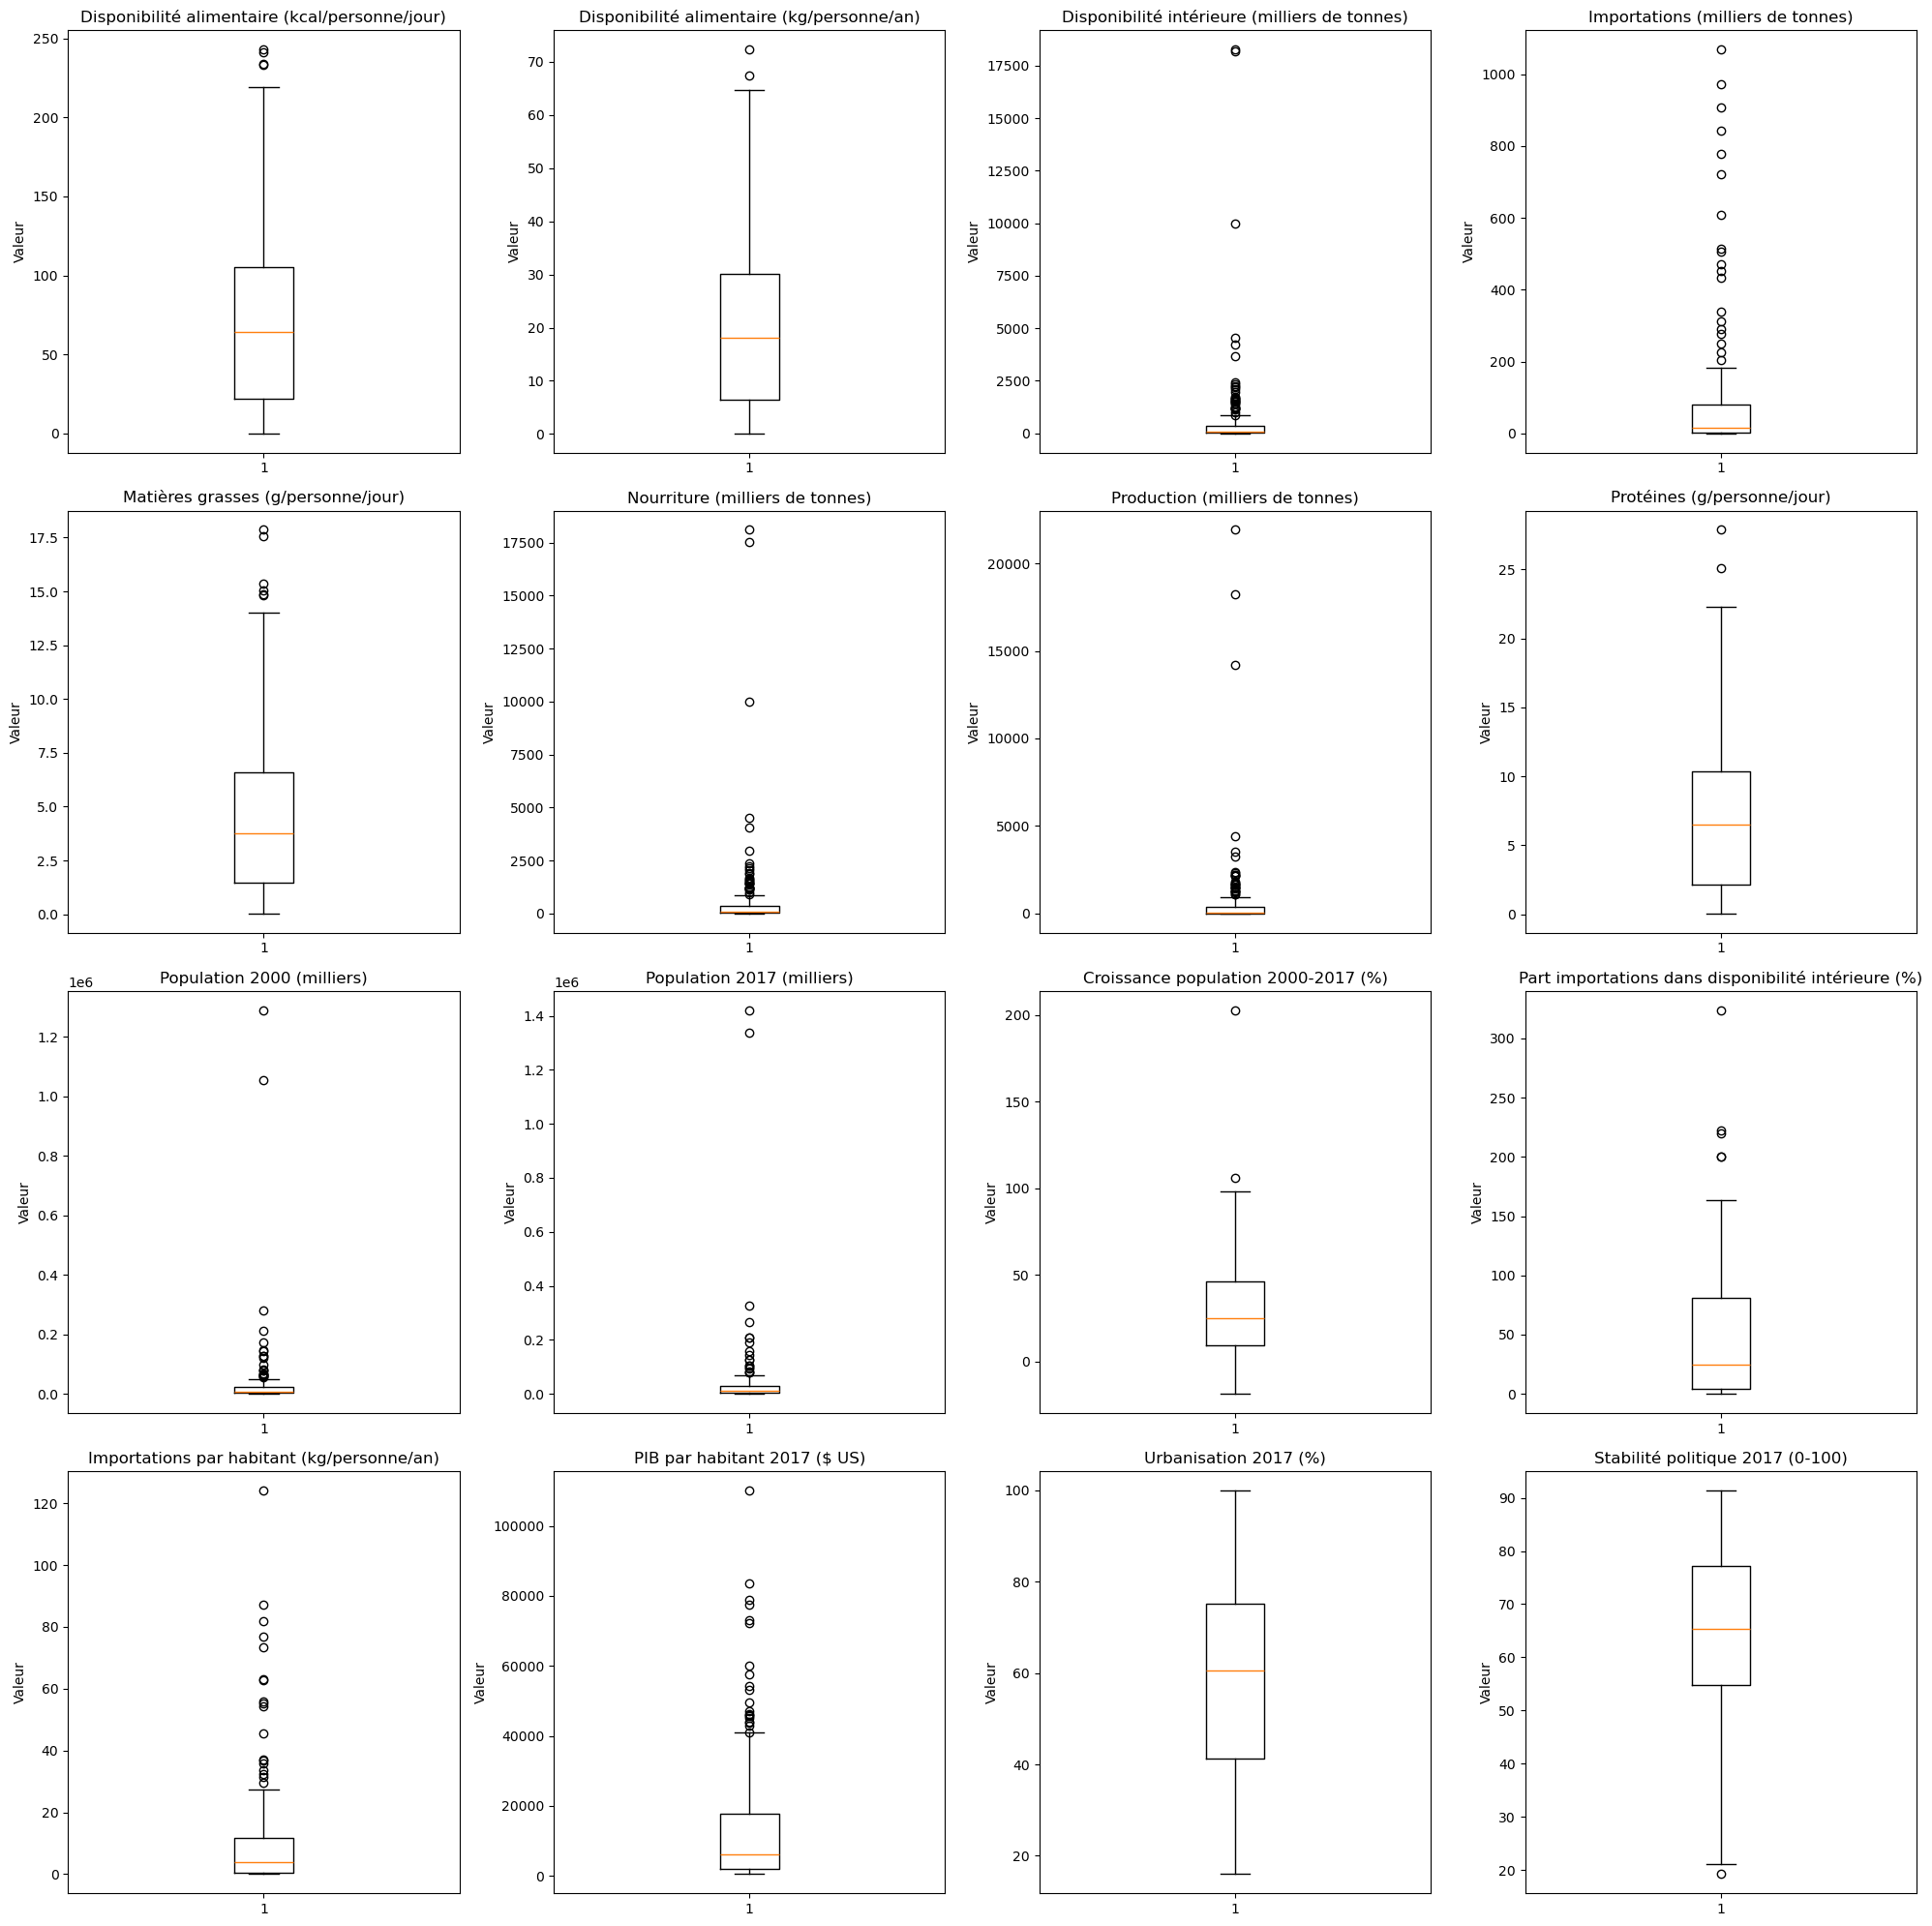

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(20, 20))

axes = axes.flatten()

for i, variable in enumerate(variables):
    axes[i].boxplot(df[variable].dropna())
    axes[i].set_title(variable)
    axes[i].set_ylabel("Valeur")

plt.tight_layout()
plt.show()

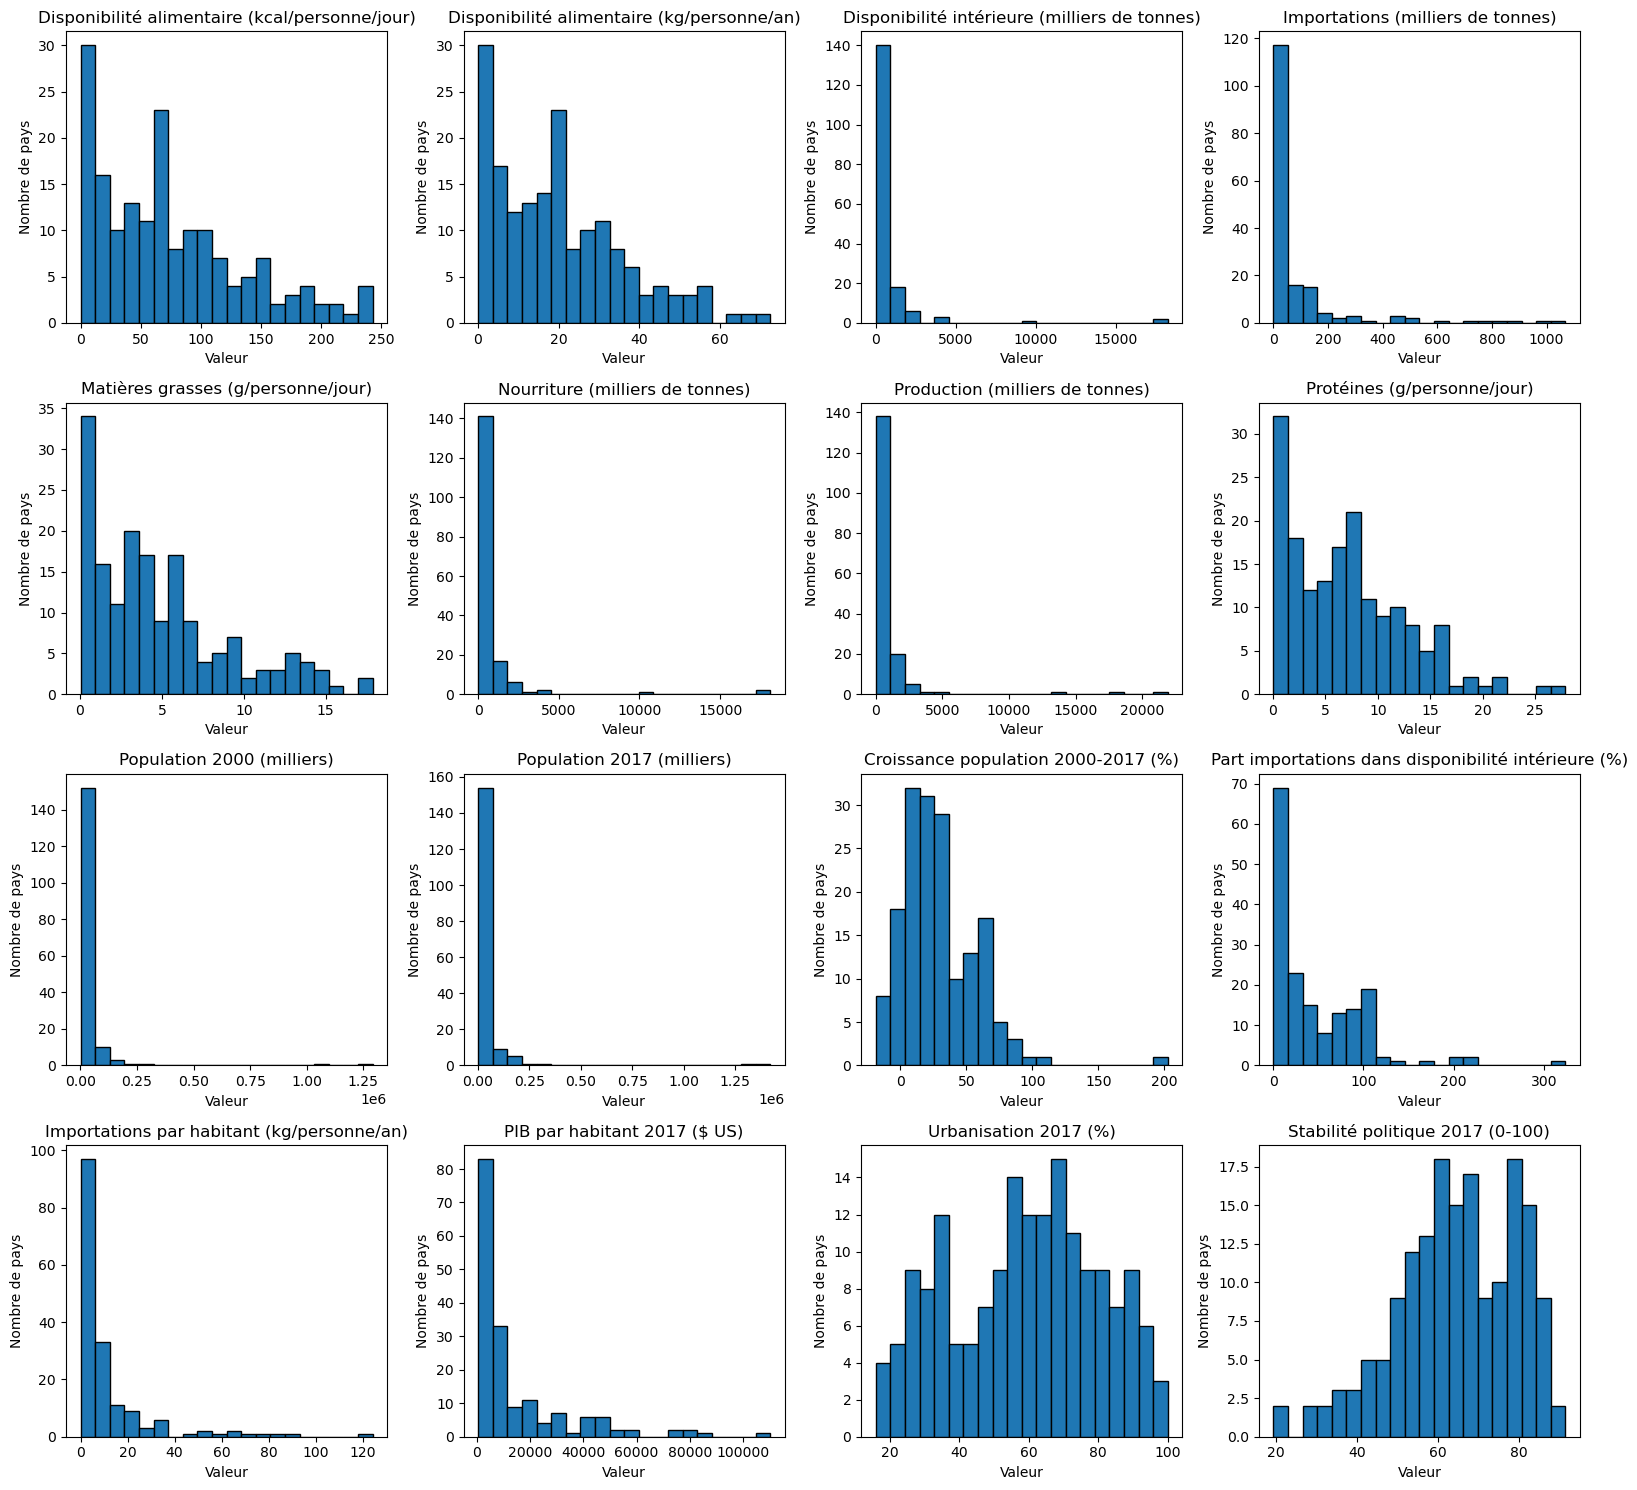

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(16, 15))

axes = axes.flatten()

for i, variable in enumerate(variables):
    axes[i].hist(df[variable].dropna(), bins=20, edgecolor="black")
    axes[i].set_title(variable)
    axes[i].set_xlabel("Valeur")
    axes[i].set_ylabel("Nombre de pays")

plt.tight_layout()
plt.show()

Plusieurs indicateurs de volume, notamment la production, la disponibilité intérieure et la population, présentent une forte asymétrie à droite : quelques zones ont des valeurs beaucoup plus élevées que les autres. Ces valeurs peuvent refléter la taille des marchés ; elles ne constituent pas, à elles seules, des erreurs.

Les indicateurs par habitant peuvent également être asymétriques. Le centrage-réduction permettra de comparer les échelles, mais ne supprimera ni l’asymétrie ni l’influence des observations extrêmes.

## <span style="color: DarkViolet;">1.3. Examiner les corrélations et sélectionner les variables</span>

La matrice des **corrélations de Pearson** aide à repérer les indicateurs qui apportent une information proche. Les corrélations sont calculées sur les observations disponibles pour chaque paire ; le nombre de zones utilisé peut donc varier. Une forte corrélation n’implique pas nécessairement un lien de causalité.

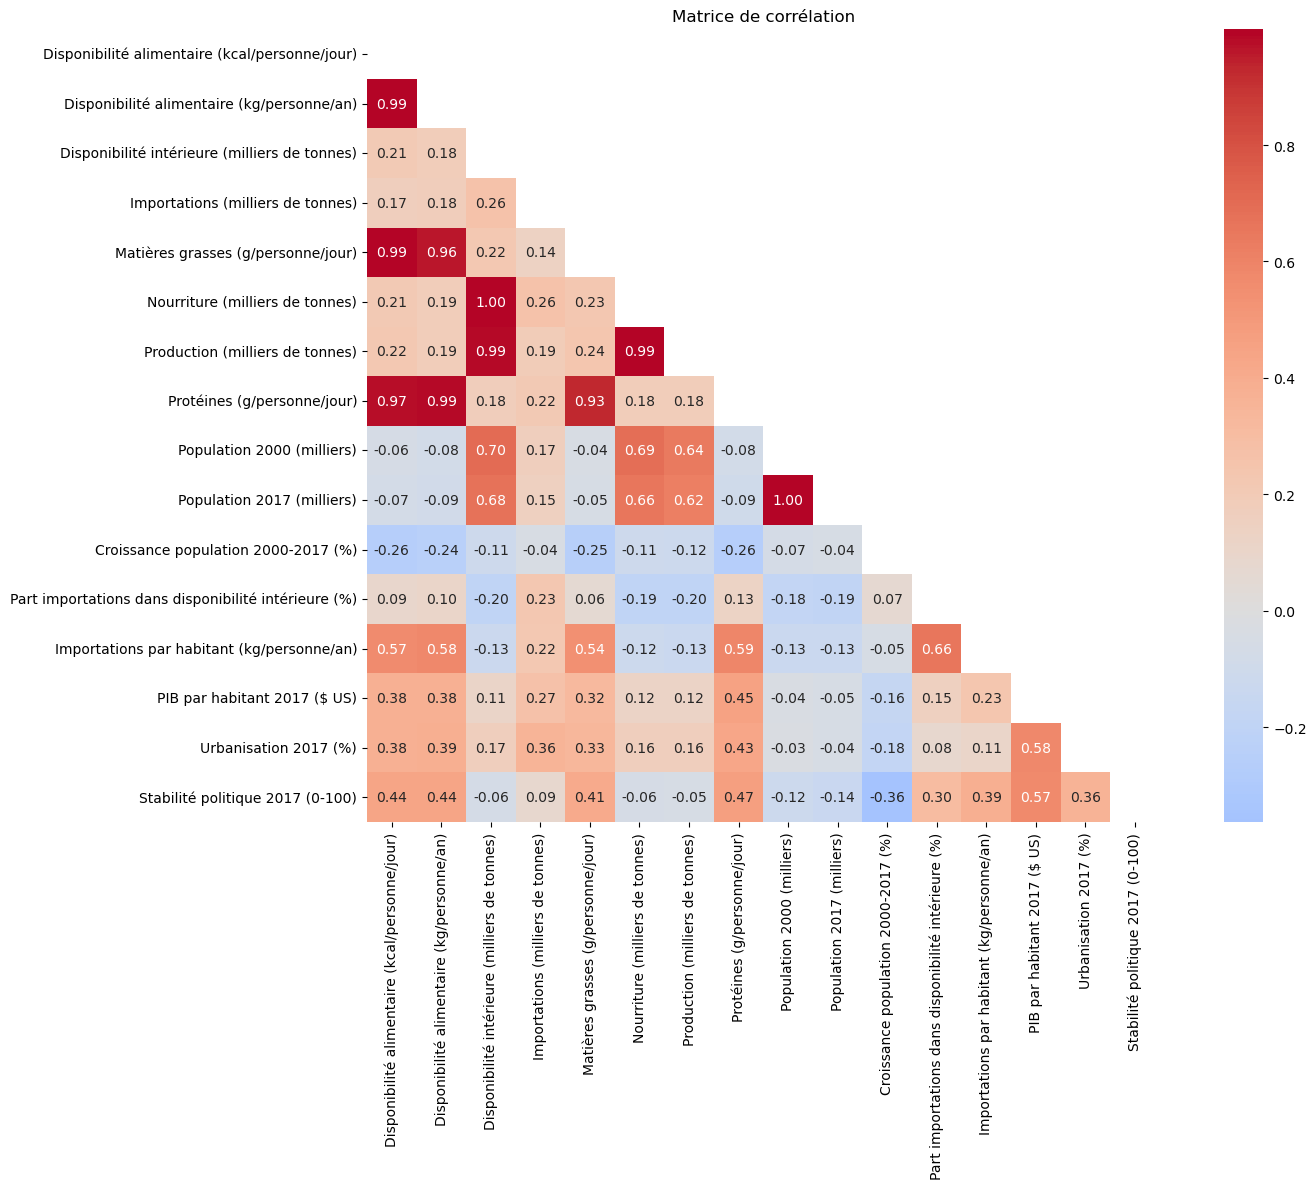

In [9]:
import seaborn as sns

corr = df[variables].corr()

# Masquer la moitié supérieure de la matrice de corrélation.
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(16, 12))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,square=True)

plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

Les indicateurs de disponibilité alimentaire en kcal, en kg, en matières grasses et en protéines présentent des corrélations comprises entre **0,927 et 0,989**. La **disponibilité alimentaire en kg/personne/an** est retenue pour limiter leur redondance.

Les corrélations entre disponibilité intérieure, nourriture et production vont de **0,988 à 0,999**. La **production** est conservée comme indicateur de capacité productive. Parmi les populations de 2000 et 2017, fortement corrélées, seule la **population de 2017** est retenue ; la croissance 2000–2017 représente l’évolution démographique.

Les **importations par habitant** rapportent les volumes importés à la population. Le **ratio des importations à la disponibilité intérieure**, peut dépasser 100 % : il ne mesure pas directement une part de consommation importée ni une autonomie productive.

Le **PIB par habitant**, l’**urbanisation** et la **stabilité politique** complètent ces dimensions. Leurs corrélations mutuelles sont comprises entre **0,365 et 0,579**.

La sélection finale comprend **9 indicateurs quantitatifs et 2 identifiants**, soit **11 colonnes**. Elle réduit certaines redondances sans rendre tous les indicateurs indépendants.

In [10]:
variables_finales = [
    "Production (milliers de tonnes)",
    "Importations par habitant (kg/personne/an)",
    "Disponibilité alimentaire (kg/personne/an)",
    "Part importations dans disponibilité intérieure (%)",
    "PIB par habitant 2017 ($ US)",
    "Population 2017 (milliers)",
    "Croissance population 2000-2017 (%)",
    "Stabilité politique 2017 (0-100)",
    "Urbanisation 2017 (%)"
]
df = df[
    ["Zone", "Code ISO3"] + variables_finales
].copy()

In [11]:
df.head(3)

,Zone,Code ISO3,Production (milliers de tonnes),Importations par habitant (kg/personne/an),Disponibilité alimentaire (kg/personne/an),Part importations dans disponibilité intérieure (%),PIB par habitant 2017 ($ US),Population 2017 (milliers),Croissance population 2000-2017 (%),Stabilité politique 2017 (0-100),Urbanisation 2017 (%)
0,Arménie,ARM,11.0,11.885394,16.06,74.468085,3869.053739,2944.791,-4.065688,60.742784,64.712495
1,Afghanistan,AFG,28.0,0.798984,1.53,50.877193,525.469771,36296.113,74.668889,21.244270,24.835282
2,Albanie,ALB,13.0,13.175372,16.36,80.851064,5006.360130,2884.169,-7.831734,68.692869,55.980276


In [12]:
df.describe().T.style.format('{:.2f}')

,count,mean,std,min,25%,50%,75%,max
Production (milliers de tonnes),168.00,725.19,2501.46,0.00,13.75,70.00,409.75,21914.00
Importations par habitant (kg/personne/an),170.00,11.02,18.68,0.00,0.47,3.97,11.82,124.14
Disponibilité alimentaire (kg/personne/an),172.00,20.21,15.86,0.13,6.44,18.09,30.04,72.31
Part importations dans disponibilité intérieure (%),170.00,45.80,51.85,0.00,4.23,24.75,80.64,323.93
PIB par habitant 2017 ($ US),170.00,14224.39,19387.26,432.32,2045.11,6025.23,17625.67,110193.21
Population 2017 (milliers),172.00,42841.75,153063.71,52.05,2874.48,9757.83,30138.74,1421021.79
Croissance population 2000-2017 (%),169.00,29.36,28.82,-18.75,9.30,25.06,46.06,202.71
Stabilité politique 2017 (0-100),169.00,64.44,14.77,19.25,54.73,65.41,77.22,91.39
Urbanisation 2017 (%),171.00,58.98,21.49,15.96,41.26,60.62,75.26,100.00


## <span style="color: LimeGreen;">2. Traiter les valeurs manquantes</span>

### <span style="color: LimeGreen;">2.1. Identifier les zones concernées</span>

In [13]:
df.isna().sum()

Zone                                                   0
Code ISO3                                              1
Production (milliers de tonnes)                        4
Importations par habitant (kg/personne/an)             2
Disponibilité alimentaire (kg/personne/an)             0
Part importations dans disponibilité intérieure (%)    2
PIB par habitant 2017 ($ US)                           2
Population 2017 (milliers)                             0
Croissance population 2000-2017 (%)                    3
Stabilité politique 2017 (0-100)                       3
Urbanisation 2017 (%)                                  1
dtype: int64

Après sélection des neuf indicateurs, **11 zones** présentent encore au moins une donnée manquante. Le tableau ci-dessous inclut aussi le code ISO3. L’analyse conserve la stratégie prévue dans le code : retrait de dix zones, puis complément manuel de Taïwan.

In [14]:
df[df.isna().any(axis=1)]

,Zone,Code ISO3,Production (milliers de tonnes),Importations par habitant (kg/personne/an),Disponibilité alimentaire (kg/personne/an),Part importations dans disponibilité intérieure (%),PIB par habitant 2017 ($ US),Population 2017 (milliers),Croissance population 2000-2017 (%),Stabilité politique 2017 (0-100),Urbanisation 2017 (%)
45,Polynésie française,PYF,1.0,54.327748,47.40,100.000000,20826.931250,276.102,14.714607,NaN,61.789694
46,Djibouti,DJI,NaN,3.177633,2.68,100.000000,2618.955211,944.099,31.566339,52.993998,71.318262
80,République populaire démocratique de Corée,PRK,43.0,0.000000,1.62,0.000000,NaN,25429.825,10.906458,59.840915,61.820608
84,République démocratique populaire lao,LAO,NaN,NaN,10.91,NaN,2432.430595,6953.035,30.605312,70.637255,34.511535
93,Maldives,MDV,NaN,24.173956,13.50,100.000000,10509.628810,496.402,77.668416,65.156839,39.327877
106,Nouvelle-Calédonie,NCL,1.0,32.473390,38.71,81.818182,32354.710280,277.150,27.560766,NaN,66.968339
145,"Chine, Taiwan Province de",NaN,652.0,6.800553,33.17,20.509554,NaN,23674.546,7.775553,NaN,NaN
160,Ouzbékistan,UZB,NaN,NaN,1.96,NaN,2271.473011,31959.785,29.026415,62.240996,50.678738
169,Serbie,SRB,85.0,1.359061,10.16,13.333333,6548.036538,8829.628,NaN,67.890373,60.621208
170,Monténégro,MNE,4.0,12.747724,15.98,80.000000,7674.285657,627.563,NaN,66.759443,64.999244


### <span style="color: LimeGreen;">2.2. Exclure les dix zones non complétées</span>

La **Polynésie française** et la **Nouvelle-Calédonie** n’ont pas de score de stabilité politique renseigné. Elles sont exclues, car de plus il s'agit des rérritoires français, or notre étude porte sur l'identification des pays étrangers comme destination des exports. 

La **République populaire démocratique de Corée** est exclue car son PIB par habitant manque dans le fichier utilisé. De plus, des restrictions et sanctions internationales imposées (non évaluées dans ce notebook) rendent ce pays moins intéressant comme partenaire commercial. 

**Djibouti** et les **Maldives** sont exclus car leur production de volaille n’est pas renseignée. La recherche parmi les sources institutionnelles n'a pas permis de retrouver des valeurs fiables de substitution. 

La **République démocratique populaire lao** et l’**Ouzbékistan** sont exclus car trois indicateurs retenus sont manquants : la production, les importations par habitant et le ratio des importations à la disponibilité intérieure. Les données retrouvées proviennent de séries révisées ou de définitions différentes, donc leur intégration nuirait à l’homogénéité du jeu de données.

La **Serbie**, le **Monténégro** et le **Soudan** sont exclus car leur croissance démographique 2000–2017 est manquante. En effet, cette valeur n'est pas calculable de façon certaine notamment à cause des changements de périmètre territorial

Ces dix exclusions conduisent à un échantillon de **162 zones**. 

In [15]:
pays_a_supprimer = ["Polynésie française", "Nouvelle-Calédonie", 
    "République populaire démocratique de Corée", "Maldives", "Djibouti",
    "République démocratique populaire lao", "Ouzbékistan",
    "Serbie", "Monténégro","Soudan"]

df = df[~df["Zone"].isin(pays_a_supprimer)].copy()

### <span style="color: LimeGreen;">2.3. Compléter manuellement les données de Taïwan</span>

Pour le taiwan ces trois valeurs ont été trouvées dans des sources officielles et ajoutées manuellement : **25 121 dollars US par habitant**, **77,8 % d’urbanisation** et **75,94339752** pour le score de stabilité politique. 

(sources :
https://www.worldometers.info/fr/pib/taiwan-pib/
https://population.un.org/wup/
https://querytab.com/dataset/taiwan-china-political-stability-and-absence-of-violenceterrorism-percentile-rank/1362269)


In [16]:
taiwan = df["Zone"] == "Chine, Taiwan Province de"
df.loc[taiwan, "Code ISO3"] = "TWN"
df.loc[taiwan, "PIB par habitant 2017 ($ US)"] = 25121
df.loc[taiwan, "Urbanisation 2017 (%)"] = 77.8
df.loc[taiwan, "Stabilité politique 2017 (0-100)"] = 75.94339752

## <span style="color: LimeGreen;">3. Réaliser une première ACP sur 162 zones</span>

### <span style="color: LimeGreen;">3.1. Centrer et réduire les neuf indicateurs</span>

L’analyse en composantes principales (ACP) part des **9 indicateurs quantitatifs** retenus. Elle construit des axes qui résument leur variabilité ; le nombre d’axes conservés détermine la part de variance représentée.

Avant l’ACP, `StandardScaler` centre chaque indicateur et le réduit à un écart-type de 1. Les unités d’origine ne déterminent ainsi plus directement leur poids. Le contrôle préalable vérifie l’absence de valeur manquante dans les neuf indicateurs.

In [17]:
# Définir les neuf indicateurs quantitatifs utilisés dans l’ACP.

variables_acp = variables_finales.copy()

In [18]:
# Vérifier l’absence de valeurs manquantes dans les indicateurs de l’ACP.
df[variables_acp].isna().sum()

Production (milliers de tonnes)                        0
Importations par habitant (kg/personne/an)             0
Disponibilité alimentaire (kg/personne/an)             0
Part importations dans disponibilité intérieure (%)    0
PIB par habitant 2017 ($ US)                           0
Population 2017 (milliers)                             0
Croissance population 2000-2017 (%)                    0
Stabilité politique 2017 (0-100)                       0
Urbanisation 2017 (%)                                  0
dtype: int64

In [19]:
# Centrer et réduire chaque indicateur. 

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[variables_acp])

In [20]:
print("Moyenne :", X_scaled.mean())
print("Écart-type :", X_scaled.std())

Moyenne : 1.827527612551698e-18
Écart-type : 1.0


Le contrôle affiché porte sur la moyenne et l’écart-type de **l’ensemble de la matrice** : environ 0 et 1. Le centrage-réduction est réalisé colonne par colonne par `StandardScaler`

### <span style="color: LimeGreen;">3.2. Choisir le nombre de composantes</span>

L’ACP est d’abord calculée sur les neuf dimensions pour examiner la variance expliquée par chaque axe et son cumul.

In [21]:
# Calculer l’ACP complète avant de choisir le nombre d’axes à conserver.

from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

In [22]:
# Calculer la variance expliquée par chaque composante et son cumul.
variance_expliquee = pca.explained_variance_ratio_ * 100
variance_cumulee = np.cumsum(variance_expliquee)

for i, (variance, cumul) in enumerate(
    zip(variance_expliquee, variance_cumulee), start=1
):
    print(
        f"F{i} : {variance:.2f} % "
        f"- cumulée : {cumul:.2f} %"
    )

F1 : 32.43 % - cumulée : 32.43 %
F2 : 21.10 % - cumulée : 53.53 %
F3 : 13.35 % - cumulée : 66.89 %
F4 : 10.50 % - cumulée : 77.39 %
F5 : 8.46 % - cumulée : 85.85 %
F6 : 5.61 % - cumulée : 91.45 %
F7 : 3.79 % - cumulée : 95.25 %
F8 : 3.43 % - cumulée : 98.67 %
F9 : 1.33 % - cumulée : 100.00 %


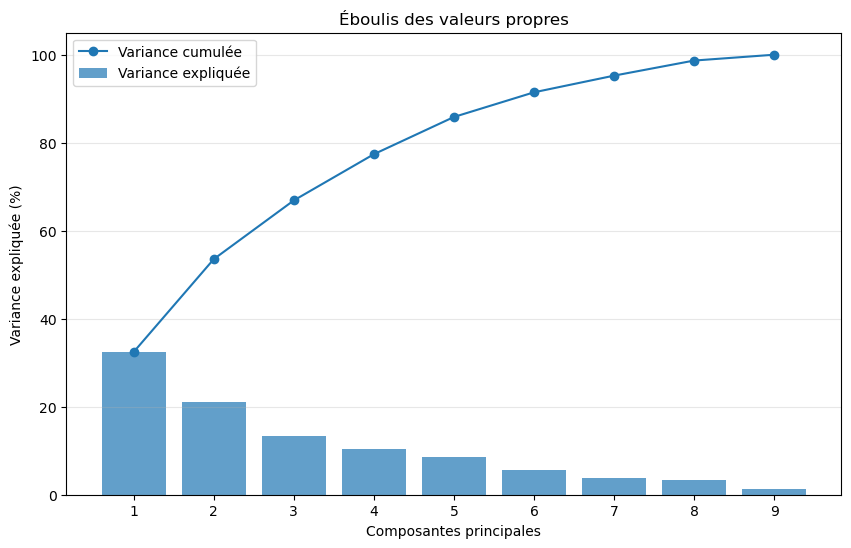

In [23]:
plt.figure(figsize=(10, 6))

plt.bar(
    range(1, len(variance_expliquee) + 1),
    variance_expliquee,
    alpha=0.7,
    label="Variance expliquée"
)

plt.plot(
    range(1, len(variance_cumulee) + 1),
    variance_cumulee,
    marker="o",
    label="Variance cumulée"
)

plt.xlabel("Composantes principales")
plt.ylabel("Variance expliquée (%)")
plt.xticks(range(1, len(variance_expliquee) + 1))
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.title("Éboulis des valeurs propres")
plt.show()

Les **3 premiers axes** expliquent **66,89 %** de la variance ; les **4 premiers** en expliquent **77,39 %**. Quatre axes sont conservés pour les classifications de cette première analyse, ce qui laisse **22,61 %** de la variance hors de cet espace.

### <span style="color: LimeGreen;"> 3.3. Interpréter les axes à partir des corrélations</span>

Les corrélations entre les variables d’origine et les quatre premiers axes permettent d’en proposer une lecture. Le signe d’un axe est conventionnel : ce sont les associations et oppositions qui comptent.

In [24]:
# Calculer les coordonnées des zones sur les axes de l’ACP.
df_pca = pd.DataFrame(
    X_pca,
    columns=[f"F{i+1}" for i in range(X_pca.shape[1])],
    index=df.index
)

# Calculer les corrélations entre les indicateurs et les axes.
correlations_axes = pd.concat(
    [df[variables_acp], df_pca],
    axis=1
).corr().loc[variables_acp, ["F1", "F2", "F3", "F4"]]

correlations_axes.round(2)

,F1,F2,F3,F4
Production (milliers de tonnes),0.00,0.83,0.39,0.07
Importations par habitant (kg/personne/an),0.68,-0.37,0.54,-0.09
Disponibilité alimentaire (kg/personne/an),0.72,0.17,0.14,-0.13
Part importations dans disponibilité intérieure (%),0.48,-0.53,0.48,0.09
PIB par habitant 2017 ($ US),0.72,0.25,-0.25,0.36
Population 2017 (milliers),-0.21,0.70,0.52,0.01
Croissance population 2000-2017 (%),-0.36,-0.33,0.25,0.76
Stabilité politique 2017 (0-100),0.79,0.02,-0.16,-0.15
Urbanisation 2017 (%),0.61,0.34,-0.31,0.41


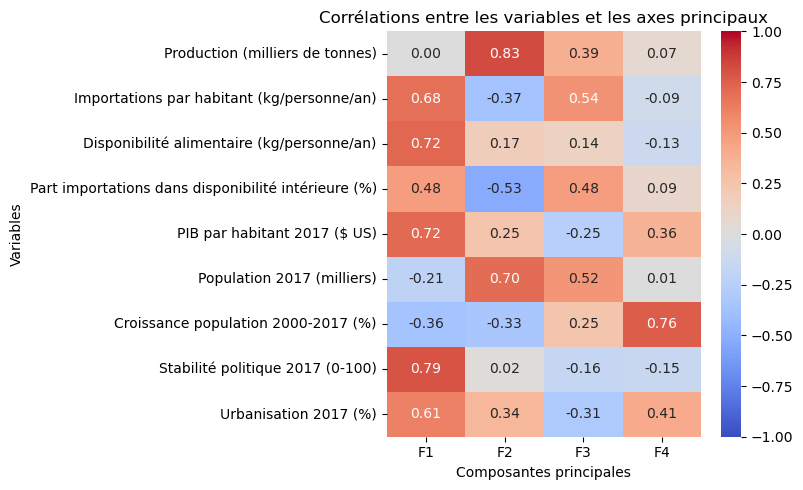

In [25]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlations_axes,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Corrélations entre les variables et les axes principaux")
plt.xlabel("Composantes principales")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

Les interprétations suivantes se rapportent aux corrélations affichées et au périmètre de **162 zones**.

**F1 — Indicateurs économiques et disponibilité alimentaire.** Le côté positif est associé à la stabilité politique (**0,79**), au PIB par habitant (**0,72**), à la disponibilité alimentaire (**0,72**), aux importations par habitant (**0,68**) et à l’urbanisation (**0,61**).

**F2 — Population et production.** Le côté positif est surtout associé à la production (**0,83**) et à la population (**0,70**), tandis que le ratio importations/disponibilité intérieure est associé au côté négatif (**−0,53**). Cet axe oppose donc des profils de taille et de production à des ratios d’importation plus élevés.

**F3 — Dimension mixte de population et d’importations.** Les associations positives les plus marquées concernent les importations par habitant (**0,54**), la population (**0,52**) et le ratio importations/disponibilité intérieure (**0,48**).

**F4 — Croissance démographique.** Cet axe est surtout associé à la croissance 2000–2017 (**0,76**), puis à l’urbanisation (**0,41**) et au PIB par habitant (**0,36**).

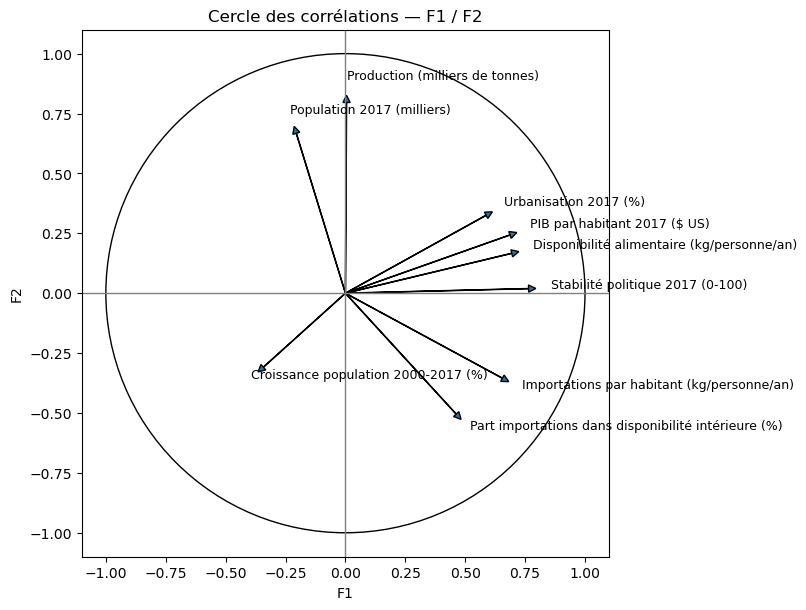

In [26]:
# Représenter les corrélations des indicateurs avec F1 et F2.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))

# Tracer le cercle unité.
cercle = plt.Circle((0, 0), 1, fill=False, color="black")
ax.add_patch(cercle)

# Tracer les axes passant par l’origine.
ax.axhline(0, color="grey", linewidth=1)
ax.axvline(0, color="grey", linewidth=1)

# Tracer les vecteurs et les noms des indicateurs.
for variable in correlations_axes.index:
    x = correlations_axes.loc[variable, "F1"]
    y = correlations_axes.loc[variable, "F2"]

    ax.arrow(
        0, 0,
        x, y,
        head_width=0.03,
        head_length=0.03,
        length_includes_head=True
    )

    ax.text(
        x * 1.08,
        y * 1.08,
        variable,
        fontsize=9
    )

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal")

ax.set_xlabel("F1")
ax.set_ylabel("F2")
ax.set_title("Cercle des corrélations — F1 / F2")

plt.tight_layout()
plt.show()

Le plan **F1–F2** représente **53,53 %** de la variance.

### <span style="color: LimeGreen;">3.4. Projeter les zones sur les plans factoriels</span>

Les coordonnées sur F1 et F2 sont associées aux noms des zones pour faciliter la lecture du nuage.

In [27]:
# Associer les noms des zones à leurs coordonnées sur F1 et F2.
projection = pd.DataFrame({
    "Zone": df["Zone"],
    "F1": X_pca[:, 0],
    "F2": X_pca[:, 1]
})

projection.head()

,Zone,F1,F2
0,Arménie,0.074763,-0.346629
1,Afghanistan,-3.255077,-1.186190
2,Albanie,0.302858,-0.458918
3,Algérie,-1.358127,0.238105
4,Angola,-0.856769,-1.065829


Pour limiter le chevauchement des étiquettes, seules les **15 zones les plus éloignées de l’origine sur le plan F1–F2** sont nommées. Cette distance concerne deux axes, pas l’ensemble des neuf indicateurs.

In [28]:
projection["distance"] = np.sqrt(
    projection["F1"]**2 +
    projection["F2"]**2
)

pays_extremes = projection.nlargest(15, "distance")

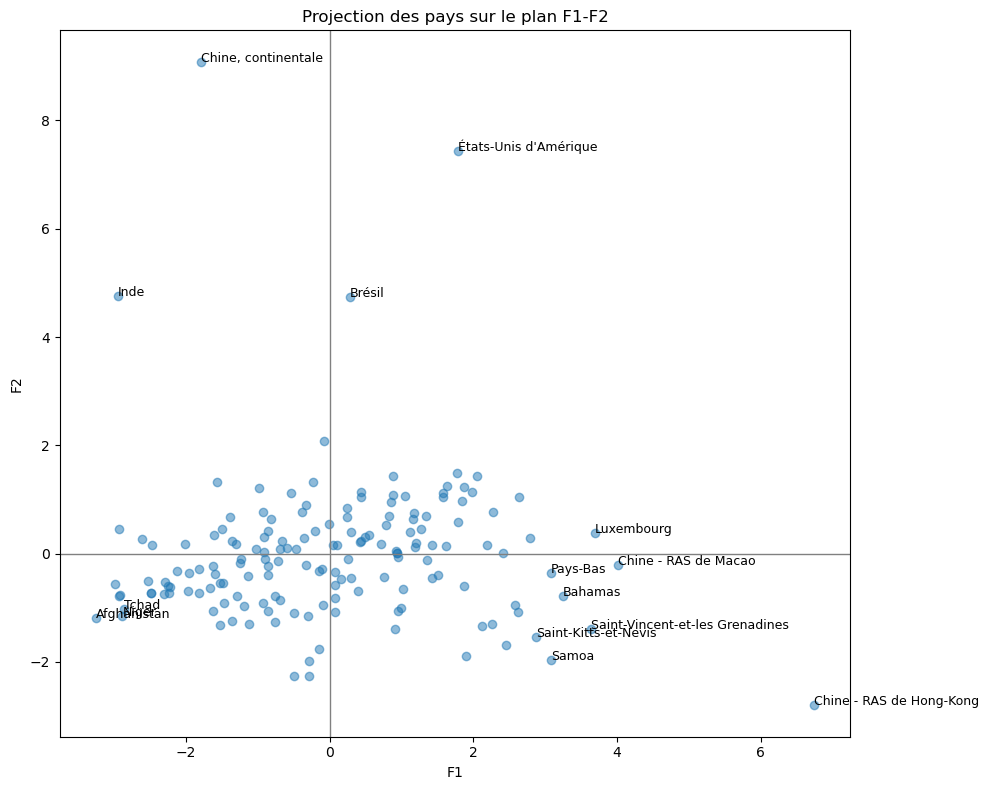

In [29]:
plt.figure(figsize=(10, 8))

plt.scatter(
    projection["F1"],
    projection["F2"],
    alpha=0.5
)

plt.axhline(0, color="grey", linewidth=1)
plt.axvline(0, color="grey", linewidth=1)

for _, ligne in pays_extremes.iterrows():
    plt.text(
        ligne["F1"],
        ligne["F2"],
        ligne["Zone"],
        fontsize=9
    )

plt.xlabel("F1")
plt.ylabel("F2")
plt.title("Projection des pays sur le plan F1-F2")

plt.tight_layout()
plt.show()

La **Chine continentale**, les **États-Unis**, l’**Inde** et le **Brésil** se distinguent notamment par leur population ou leur production. La première classification permettra de vérifier leur regroupement avant de comparer une analyse réalisée sans ces quatre zones.

Le plan **F3–F4** complète la lecture avec **23,85 %** de variance supplémentaire. Les 15 zones les plus éloignées de l’origine sur ce plan sont à nouveau étiquetées.

In [30]:
# Conserver les quatre premières composantes pour la classification.
X_pca_4 = X_pca[:, :4]

X_pca_4.shape

(162, 4)

In [31]:
# Associer les noms des zones à leurs coordonnées sur F3 et F4.
projection_f34 = pd.DataFrame({
    "Zone": df["Zone"],
    "F3": X_pca[:, 2],
    "F4": X_pca[:, 3]
})

# Calculer la distance à l’origine sur le plan F3–F4.
projection_f34["distance"] = np.sqrt(
    projection_f34["F3"]**2 +
    projection_f34["F4"]**2
)

# Sélectionner les 15 zones les plus éloignées de l’origine sur ce plan.
pays_extremes_f34 = projection_f34.nlargest(15, "distance")

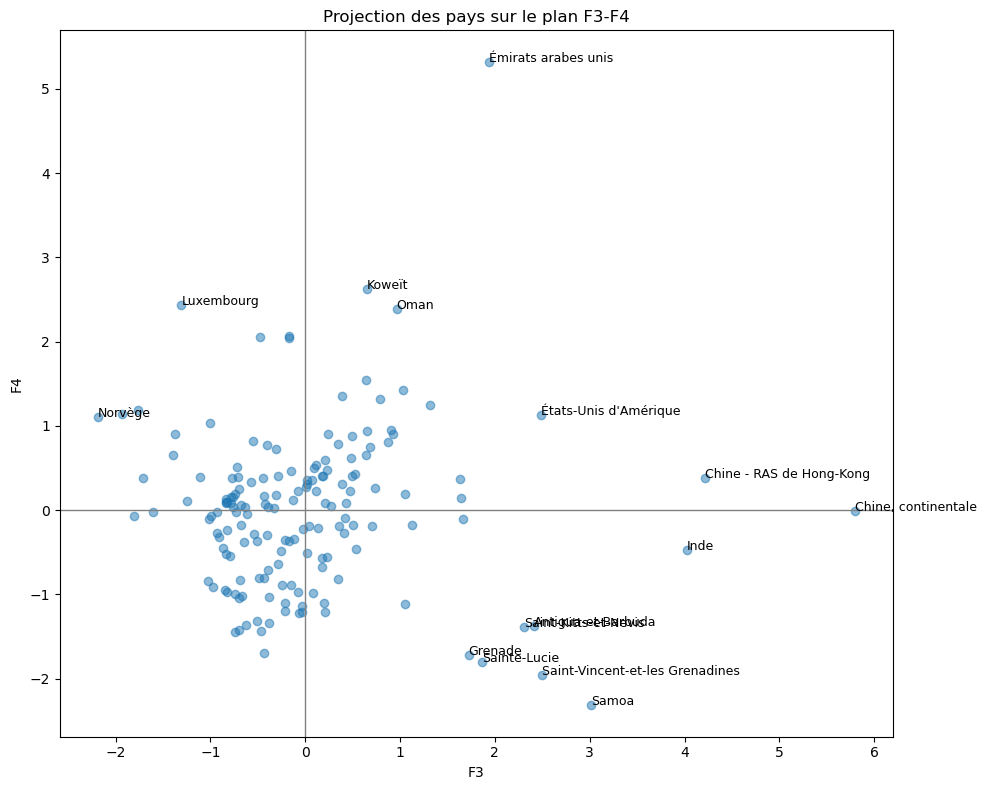

In [32]:
plt.figure(figsize=(10, 8))

plt.scatter(
    projection_f34["F3"],
    projection_f34["F4"],
    alpha=0.5
)

plt.axhline(0, color="grey", linewidth=1)
plt.axvline(0, color="grey", linewidth=1)

for _, ligne in pays_extremes_f34.iterrows():
    plt.text(
        ligne["F3"],
        ligne["F4"],
        ligne["Zone"],
        fontsize=9
    )

plt.xlabel("F3")
plt.ylabel("F4")
plt.title("Projection des pays sur le plan F3-F4")

plt.tight_layout()
plt.show()

## <span style="color:DarkOrange;"> 4. Comparer les classifications initiales sur 162 zones</span>

Les classifications utilisent les **quatre premières composantes de l’ACP**. Les moyennes de groupes sont ensuite décrites à partir des neuf indicateurs standardisés.

### <span style="color:DarkOrange;">4.1. Classification ascendante hiérarchique (CAH)</span>

La méthode de **Ward** regroupe progressivement les observations en limitant l’augmentation de l’inertie à l’intérieur des groupes. Le dendrogramme permet d’examiner les niveaux de fusion et de proposer plusieurs nombres de groupes.

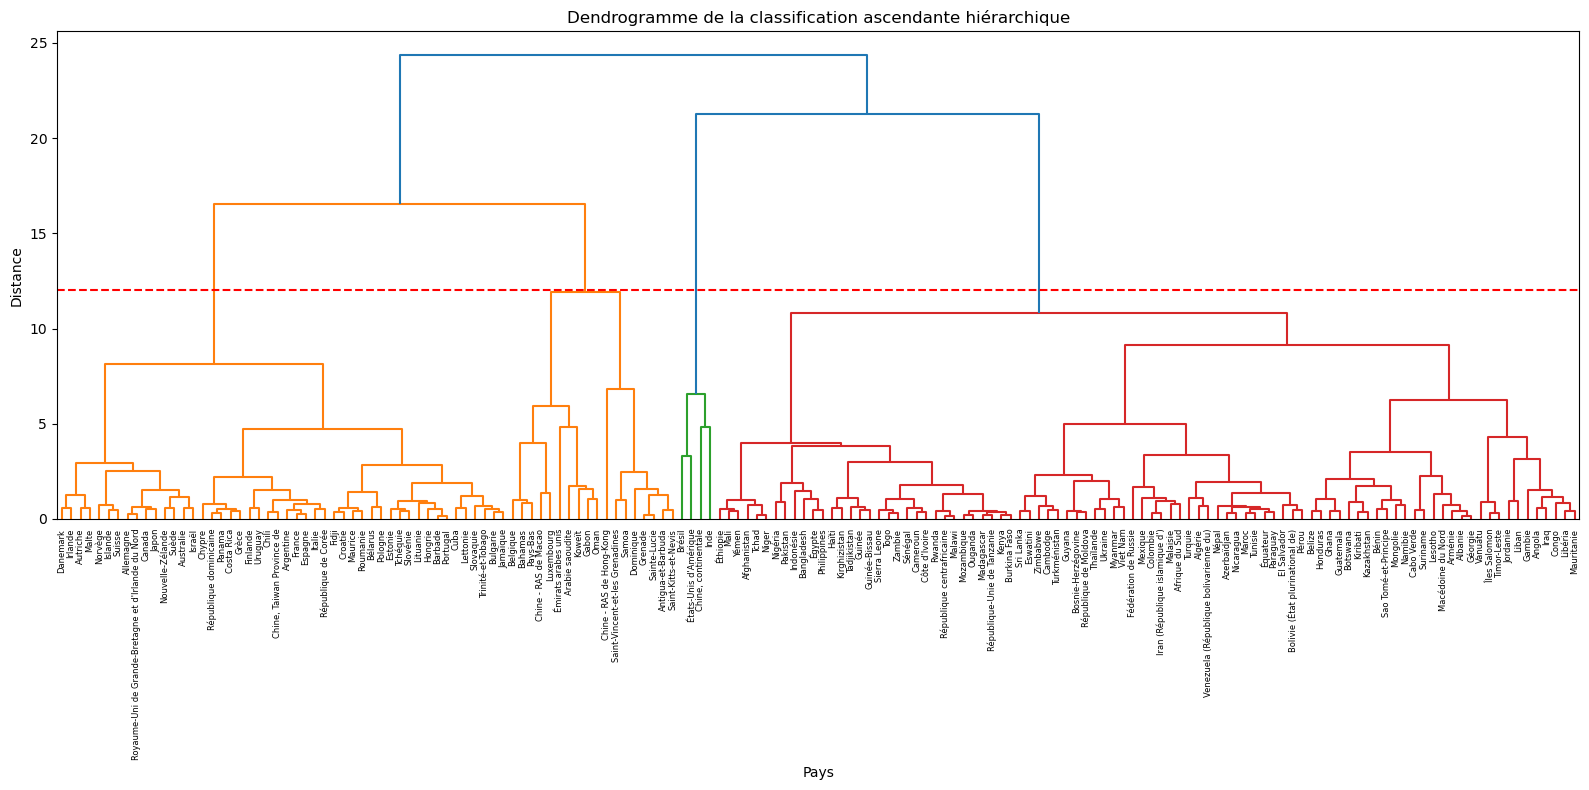

In [33]:

from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_pca_4, method="ward")

plt.figure(figsize=(16, 8))

dendrogram(
    Z,
    labels=df["Zone"].values,
    leaf_rotation=90,
    leaf_font_size=6
)
plt.axhline(
    y=12,
    color="red",
    linestyle="--"
)
plt.title("Dendrogramme de la classification ascendante hiérarchique")
plt.xlabel("Pays")
plt.ylabel("Distance")

plt.tight_layout()
# plt.savefig("dendro-v3.png", dpi=300, bbox_inches="tight")
plt.show()

Au dendrogramme a été ajouté une ligne de repère à une **hauteur de 12**. Ce seuil produit **quatre groupes**. Ce repère visuel est exploratoire ; le choix du nombre de groupes est ensuite confronté au score de silhouette.

Le score de silhouette compare la cohésion des groupes et leur séparation. Une valeur plus élevée indique une meilleure séparation selon ce critère, dans l’espace utilisé. Les solutions de **2 à 7 groupes** sont comparées.

In [34]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

for k in range(2, 8):
    cah = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = cah.fit_predict(X_pca_4)

    score = silhouette_score(X_pca_4, labels)

    print(f"{k} clusters : silhouette = {score:.3f}")

2 clusters : silhouette = 0.305
3 clusters : silhouette = 0.336
4 clusters : silhouette = 0.331
5 clusters : silhouette = 0.349
6 clusters : silhouette = 0.267
7 clusters : silhouette = 0.280


Parmi les solutions testées, **5 groupes** obtiennent le meilleur score de silhouette pour la CAH (**0,349**). Cette partition est retenue pour examiner les effectifs et les profils.

In [35]:
# Construire une partition CAH en cinq groupes.

from sklearn.cluster import AgglomerativeClustering

cah = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

clusters_cah = cah.fit_predict(X_pca_4)

# Numéroter les groupes de 1 à 5 au lieu de 0 à 4.
df["Cluster_CAH"] = clusters_cah + 1

In [36]:
# Afficher l’effectif de chaque groupe.
df["Cluster_CAH"].value_counts().sort_index()

Cluster_CAH
1    92
2    48
3     4
4     8
5    10
Name: count, dtype: int64

In [37]:
# Afficher les noms des zones de chaque groupe.
for cluster in sorted(df["Cluster_CAH"].unique()):
    print(f"\nCluster {cluster}")
    print(
        df.loc[df["Cluster_CAH"] == cluster, "Zone"]
        .sort_values()
        .tolist()
    )


Cluster 1
['Afghanistan', 'Afrique du Sud', 'Albanie', 'Algérie', 'Angola', 'Arménie', 'Azerbaïdjan', 'Bangladesh', 'Belize', 'Bolivie (État plurinational de)', 'Bosnie-Herzégovine', 'Botswana', 'Burkina Faso', 'Bénin', 'Cabo Verde', 'Cambodge', 'Cameroun', 'Colombie', 'Congo', "Côte d'Ivoire", 'El Salvador', 'Eswatini', 'Fédération de Russie', 'Gambie', 'Ghana', 'Guatemala', 'Guinée', 'Guinée-Bissau', 'Guyana', 'Géorgie', 'Haïti', 'Honduras', 'Indonésie', "Iran (République islamique d')", 'Iraq', 'Jordanie', 'Kazakhstan', 'Kenya', 'Kirghizistan', 'Kiribati', 'Lesotho', 'Liban', 'Libéria', 'Macédoine du Nord', 'Madagascar', 'Malaisie', 'Malawi', 'Mali', 'Maroc', 'Mauritanie', 'Mexique', 'Mongolie', 'Mozambique', 'Myanmar', 'Namibie', 'Nicaragua', 'Niger', 'Nigéria', 'Népal', 'Ouganda', 'Pakistan', 'Paraguay', 'Philippines', 'Pérou', 'Rwanda', 'République centrafricaine', 'République de Moldova', 'République-Unie de Tanzanie', 'Sao Tomé-et-Principe', 'Sierra Leone', 'Sri Lanka', 'Surin

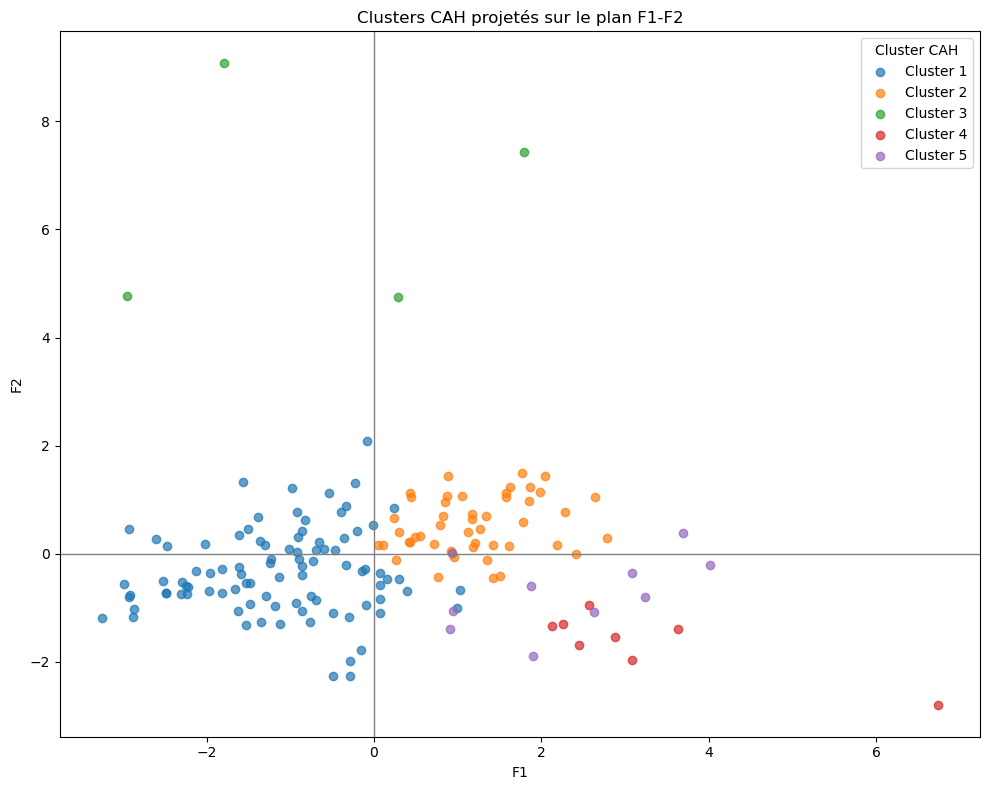

In [38]:
# Représenter les groupes CAH sur le plan F1–F2.

plt.figure(figsize=(10, 8))

for cluster in sorted(df["Cluster_CAH"].unique()):
    
    masque = df["Cluster_CAH"] == cluster
    
    plt.scatter(
        X_pca[masque, 0],
        X_pca[masque, 1],
        alpha=0.7,
        label=f"Cluster {cluster}"
    )

plt.axhline(0, color="grey", linewidth=1)
plt.axvline(0, color="grey", linewidth=1)

plt.xlabel("F1")
plt.ylabel("F2")
plt.title("Clusters CAH projetés sur le plan F1-F2")

plt.legend(title="Cluster CAH")

plt.tight_layout()
plt.show()

Les profils sont les **moyennes des indicateurs standardisés** dans chaque groupe. Une valeur positive indique une moyenne supérieure à celle des 162 zones ; une valeur négative indique une moyenne inférieure. L’unité est l’écart-type, et non le pourcentage.

In [39]:
df_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_acp,
    index=df.index
)

df_scaled["Cluster_CAH"] = df["Cluster_CAH"]

profil_cah = (
    df_scaled
    .groupby("Cluster_CAH")[variables_acp]
    .mean()
    .round(2)
    .T
)

profil_cah

Cluster_CAH,1,2,3,4,5
Production (milliers de tonnes),-0.14,-0.09,5.41,-0.29,-0.21
Importations par habitant (kg/personne/an),-0.36,-0.13,-0.57,3.57,1.30
Disponibilité alimentaire (kg/personne/an),-0.53,0.47,0.57,2.17,0.68
Part importations dans disponibilité intérieure (%),-0.12,-0.24,-0.85,1.60,1.32
PIB par habitant 2017 ($ US),-0.57,0.76,0.29,0.07,1.47
Population 2017 (milliers),-0.08,-0.17,4.96,-0.28,-0.23
Croissance population 2000-2017 (%),0.30,-0.71,-0.40,-0.60,1.27
Stabilité politique 2017 (0-100),-0.59,0.85,-0.29,1.04,0.62
Urbanisation 2017 (%),-0.43,0.65,0.26,-0.71,1.35


La CAH distingue cinq profils, décrits relativement à l’échantillon :

- **Groupe 1 — 92 zones :** PIB par habitant, stabilité, urbanisation et importations par habitant inférieurs à la moyenne.
- **Groupe 2 — 48 zones :** PIB par habitant, stabilité et urbanisation supérieurs à la moyenne, avec un ratio d’importation inférieur à la moyenne.
- **Groupe 3 — 4 zones :** Chine continentale, États-Unis, Inde et Brésil ; la production et la population y sont très supérieures à la moyenne.
- **Groupe 4 — 8 zones :** faible population, forte disponibilité alimentaire et importations par habitant élevées.
- **Groupe 5 — 10 zones :** PIB par habitant, urbanisation, croissance démographique et indicateurs d’importation supérieurs à la moyenne.

Les groupes 4 et 5 constituent des profils à approfondir pour une étude d’exportation.

### <span style="color:DarkOrange;">4.2. Classification par K-means</span>

K-means est évalué indépendamment de la CAH pour **2 à 7 groupes**. L’inertie et le score de silhouette complètent l’examen des partitions.

In [40]:
from sklearn.cluster import KMeans

inerties = []
silhouettes = []

K = range(2, 8)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    
    labels = kmeans.fit_predict(X_pca_4)
    
    inerties.append(kmeans.inertia_)
    silhouettes.append(
        silhouette_score(X_pca_4, labels)
    )

    print(
        f"{k} clusters : "
        f"silhouette = {silhouettes[-1]:.3f}"
    )

C:\Users\Vecto\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Vecto\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Vecto\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Vecto\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^

2 clusters : silhouette = 0.318
3 clusters : silhouette = 0.340
4 clusters : silhouette = 0.354


C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


5 clusters : silhouette = 0.327
6 clusters : silhouette = 0.323


C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


7 clusters : silhouette = 0.292


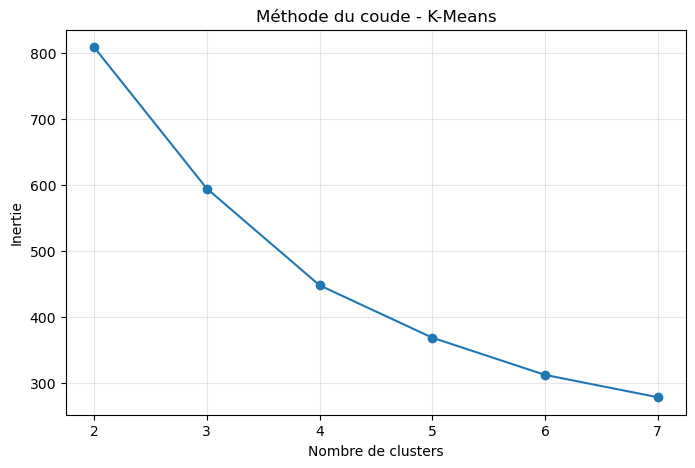

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(K, inerties, marker="o")

plt.xlabel("Nombre de clusters")
plt.ylabel("Inertie")
plt.title("Méthode du coude - K-Means")

plt.xticks(list(K))
plt.grid(alpha=0.3)

plt.show()

Pour K-means, le meilleur score de silhouette parmi les valeurs testées est obtenu avec **4 groupes : 0,354**. Cette partition est retenue pour la première analyse, alors que la CAH en conserve cinq.

In [42]:
#from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

df["Cluster_KMeans"] = kmeans.fit_predict(X_pca_4) + 1

C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [43]:
# Afficher l’effectif de chaque groupe.
df["Cluster_KMeans"].value_counts().sort_index()

Cluster_KMeans
1    72
2    16
3     4
4    70
Name: count, dtype: int64

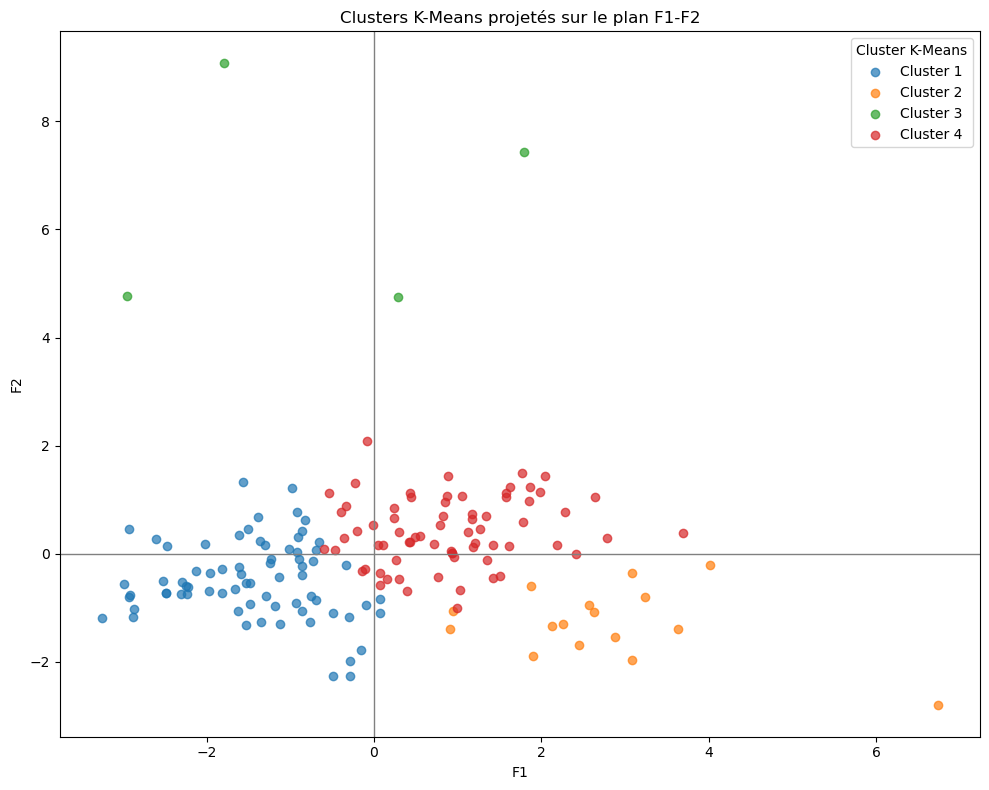

In [44]:
# Représenter les groupes K-means sur le plan F1–F2.
plt.figure(figsize=(10, 8))

for cluster in sorted(df["Cluster_KMeans"].unique()):
    
    masque = df["Cluster_KMeans"] == cluster
    
    plt.scatter(
        X_pca[masque, 0],
        X_pca[masque, 1],
        alpha=0.7,
        label=f"Cluster {cluster}"
    )

plt.axhline(0, color="grey", linewidth=1)
plt.axvline(0, color="grey", linewidth=1)

plt.xlabel("F1")
plt.ylabel("F2")
plt.title("Clusters K-Means projetés sur le plan F1-F2")

plt.legend(title="Cluster K-Means")
plt.tight_layout()
plt.show()

In [45]:
# Calculer les moyennes standardisées des quatre groupes.

df_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_acp,
    index=df.index
)

df_scaled["Cluster_KMeans"] = df["Cluster_KMeans"]

profil_kmeans = (
    df_scaled
    .groupby("Cluster_KMeans")[variables_acp]
    .mean()
    .round(2)
    .T
)

profil_kmeans

Cluster_KMeans,1,2,3,4
Production (milliers de tonnes),-0.19,-0.25,5.41,-0.05
Importations par habitant (kg/personne/an),-0.42,2.53,-0.57,-0.12
Disponibilité alimentaire (kg/personne/an),-0.74,1.43,0.57,0.40
Part importations dans disponibilité intérieure (%),-0.12,1.55,-0.85,-0.18
PIB par habitant 2017 ($ US),-0.61,0.62,0.29,0.47
Population 2017 (milliers),-0.07,-0.26,4.96,-0.15
Croissance population 2000-2017 (%),0.52,0.41,-0.40,-0.61
Stabilité politique 2017 (0-100),-0.74,0.86,-0.29,0.58
Urbanisation 2017 (%),-0.62,0.32,0.26,0.55


Les deux méthodes regroupent la Chine continentale, les États-Unis, l’Inde et le Brésil dans un groupe de **4 zones** caractérisé par des niveaux de population et de production très élevés.

Une seconde analyse les exclut afin d’examiner plus finement la structure du reste de l’échantillon. Il s’agit d’un **changement de périmètre exploratoire**, pas d’une correction de données erronées ni d’une preuve que ces marchés doivent être écartés commercialement.

## <span style="color: DodgerBlue;">5. Recalculer l’ACP après retrait de quatre grandes zones</span>

### <span style="color: DodgerBlue;">5.1. Constituer le périmètre de 158 zones</span>

Les quatre zones sont retirées, les anciennes étiquettes de groupes supprimées et l’index réinitialisé. La suite porte sur **158 zones et 9 indicateurs**.

In [46]:
# Retirer les quatre grandes zones pour la seconde analyse.

pays_atypiques = ["Chine, continentale", "États-Unis d'Amérique", "Inde", "Brésil"]

df = df[~df["Zone"].isin(pays_atypiques)].copy()

# Supprimer les anciennes étiquettes de groupes,
# qui seront recalculées sur le nouvel échantillon.
df = df.drop(
    columns=["Cluster_CAH", "Cluster_KMeans"],
    errors="ignore"
)

df = df.reset_index(drop=True)

In [47]:
df["Zone"].isin(pays_atypiques).sum()

np.int64(0)

### <span style="color: DodgerBlue;">5.2. Recalculer le centrage-réduction et l’ACP</span>

Les moyennes, les écarts-types et les axes sont recalculés sur les **158 zones restantes**. Cette étape est nécessaire : retirer des lignes sans réestimer ces paramètres conserverait la référence de l’ancien échantillon.

In [48]:
# from sklearn.preprocessing import StandardScaler
# from sklearn.decomposition import PCA

# 1. Centrer et réduire les indicateurs sur les 158 zones restantes.
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    df[variables_acp]
)

# 2. Recalculer l’ACP sur ce périmètre.
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

# 3. Conserver les quatre premières composantes.
X_pca_4 = X_pca[:, :4]

In [49]:
print("df :", df.shape)
print("X_scaled :", X_scaled.shape)
print("X_pca :", X_pca.shape)
print("X_pca_4 :", X_pca_4.shape)

df : (158, 11)
X_scaled : (158, 9)
X_pca : (158, 9)
X_pca_4 : (158, 4)


In [50]:
print(np.round(X_scaled.mean(axis=0), 2))
print(np.round(X_scaled.std(axis=0), 2))

[ 0.  0.  0.  0.  0. -0.  0.  0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [51]:
variance_expliquee = pca.explained_variance_ratio_ * 100
variance_cumulee = np.cumsum(variance_expliquee)

for i, (var, cumul) in enumerate(
    zip(variance_expliquee, variance_cumulee),
    start=1
):
    print(f"F{i} : {var:.2f} % — cumul : {cumul:.2f} %")

F1 : 33.95 % — cumul : 33.95 %
F2 : 22.83 % — cumul : 56.78 %
F3 : 12.28 % — cumul : 69.07 %
F4 : 10.67 % — cumul : 79.73 %
F5 : 7.79 % — cumul : 87.53 %
F6 : 5.26 % — cumul : 92.78 %
F7 : 3.49 % — cumul : 96.27 %
F8 : 2.56 % — cumul : 98.84 %
F9 : 1.16 % — cumul : 100.00 %


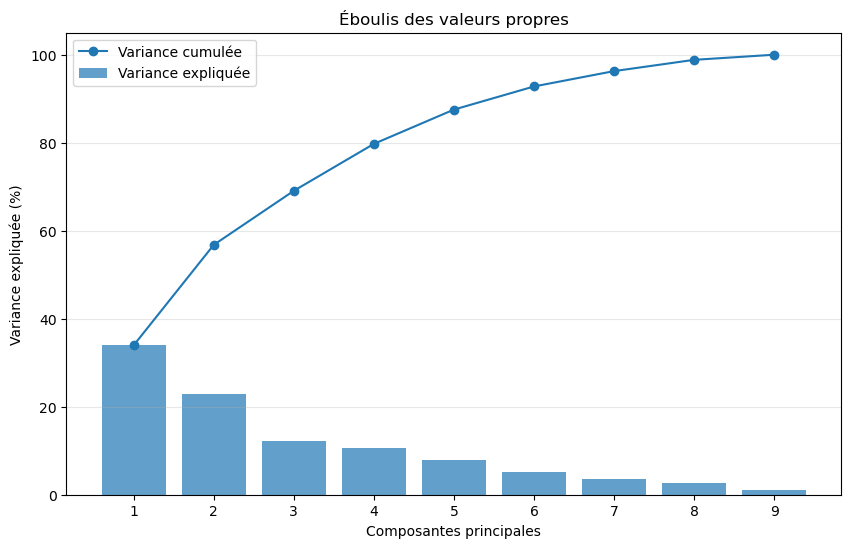

In [52]:
plt.figure(figsize=(10, 6))

plt.bar(
    range(1, len(variance_expliquee) + 1),
    variance_expliquee,
    alpha=0.7,
    label="Variance expliquée"
)

plt.plot(
    range(1, len(variance_cumulee) + 1),
    variance_cumulee,
    marker="o",
    label="Variance cumulée"
)

plt.xlabel("Composantes principales")
plt.ylabel("Variance expliquée (%)")
plt.xticks(range(1, len(variance_expliquee) + 1))
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.title("Éboulis des valeurs propres")
plt.show()

Les **3 premiers axes** expliquent **69,07 %** de la variance et les **4 premiers, 79,73 %**. F4 apporte **10,67 points de pourcentage** supplémentaires. Quatre axes sont conservés ; **20,27 %** de la variance reste hors de l’espace de classification.

### <span style="color: DodgerBlue;">5.3. Interpréter et représenter les nouveaux axes</span>

In [53]:
# Calculer les corrélations entre les indicateurs et les quatre premiers axes.
# Calculer les coordonnées des zones sur les axes.
df_pca = pd.DataFrame(
    X_pca,
    columns=[f"F{i+1}" for i in range(X_pca.shape[1])],
    index=df.index
)

# Extraire les corrélations des indicateurs avec F1 à F4.
correlations_axes = pd.concat(
    [df[variables_acp], df_pca],
    axis=1
).corr().loc[
    variables_acp,
    ["F1", "F2", "F3", "F4"]
]

correlations_axes.round(2)

,F1,F2,F3,F4
Production (milliers de tonnes),-0.15,0.86,0.31,-0.05
Importations par habitant (kg/personne/an),0.71,-0.27,0.57,-0.14
Disponibilité alimentaire (kg/personne/an),0.69,0.27,0.28,-0.24
Part importations dans disponibilité intérieure (%),0.55,-0.48,0.40,0.12
PIB par habitant 2017 ($ US),0.67,0.35,-0.22,0.42
Population 2017 (milliers),-0.49,0.61,0.44,0.05
Croissance population 2000-2017 (%),-0.33,-0.40,0.29,0.70
Stabilité politique 2017 (0-100),0.82,0.06,-0.32,-0.08
Urbanisation 2017 (%),0.54,0.53,-0.12,0.43


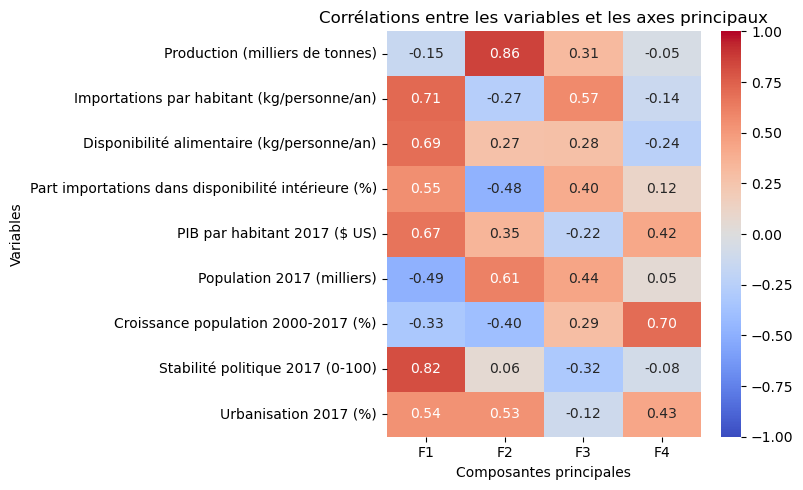

In [54]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlations_axes,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Corrélations entre les variables et les axes principaux")
plt.xlabel("Composantes principales")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

Les corrélations permettent de préciser la lecture des nouveaux axes :

- **F1 :** stabilité (**0,82**), importations par habitant (**0,71**), disponibilité alimentaire (**0,69**) et PIB par habitant (**0,67**) ; la population est associée négativement (**−0,49**).
- **F2 :** production (**0,86**), population (**0,61**) et urbanisation (**0,53**), opposées notamment au ratio d’importation (**−0,48**).
- **F3 :** importations par habitant (**0,57**), population (**0,44**) et ratio d’importation (**0,40**) ; cet axe reste mixte.
- **F4 :** croissance démographique (**0,70**), urbanisation (**0,43**) et PIB par habitant (**0,42**).

Le plan F1–F2 représente **56,78 %** de la variance et le plan F3–F4 **22,95 %**. Les étiquettes des projections désignent les 15 zones les plus éloignées de l’origine dans chaque plan.

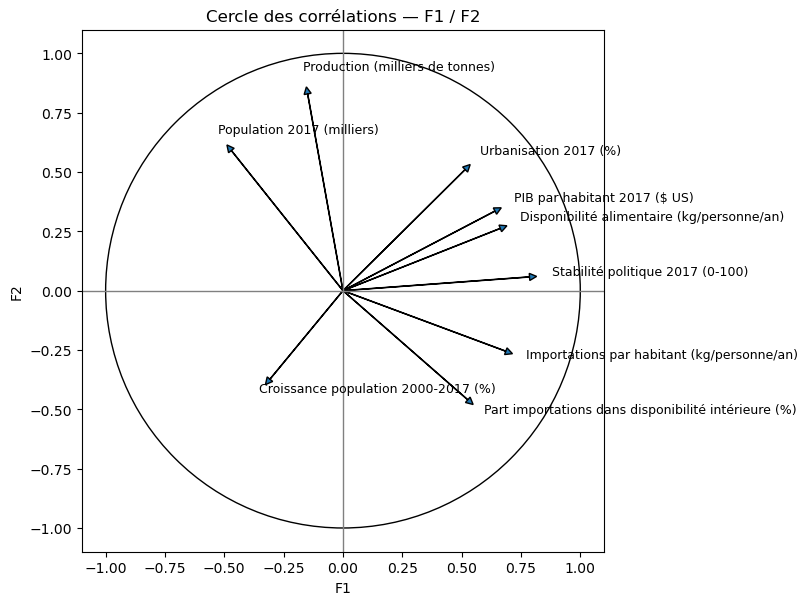

In [55]:
# Représenter les corrélations des indicateurs avec F1 et F2.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))

# Tracer le cercle unité.
cercle = plt.Circle((0, 0), 1, fill=False, color="black")
ax.add_patch(cercle)

# Tracer les axes passant par l’origine.
ax.axhline(0, color="grey", linewidth=1)
ax.axvline(0, color="grey", linewidth=1)

# Tracer les vecteurs et les noms des indicateurs.
for variable in correlations_axes.index:
    x = correlations_axes.loc[variable, "F1"]
    y = correlations_axes.loc[variable, "F2"]

    ax.arrow(
        0, 0,
        x, y,
        head_width=0.03,
        head_length=0.03,
        length_includes_head=True
    )

    ax.text(
        x * 1.08,
        y * 1.08,
        variable,
        fontsize=9
    )

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal")

ax.set_xlabel("F1")
ax.set_ylabel("F2")
ax.set_title("Cercle des corrélations — F1 / F2")

plt.tight_layout()
plt.show()

In [56]:
# Associer les noms des zones à leurs coordonnées sur F1 et F2.
projection = pd.DataFrame({
    "Zone": df["Zone"],
    "F1": X_pca[:, 0],
    "F2": X_pca[:, 1]
})

projection.head()

,Zone,F1,F2
0,Arménie,0.237565,-0.538224
1,Afghanistan,-3.109314,-1.661715
2,Albanie,0.483295,-0.663798
3,Algérie,-1.475423,0.299406
4,Angola,-0.762375,-1.176633


In [57]:
projection["distance"] = np.sqrt(
    projection["F1"]**2 +
    projection["F2"]**2
)

pays_extremes = projection.nlargest(15, "distance")

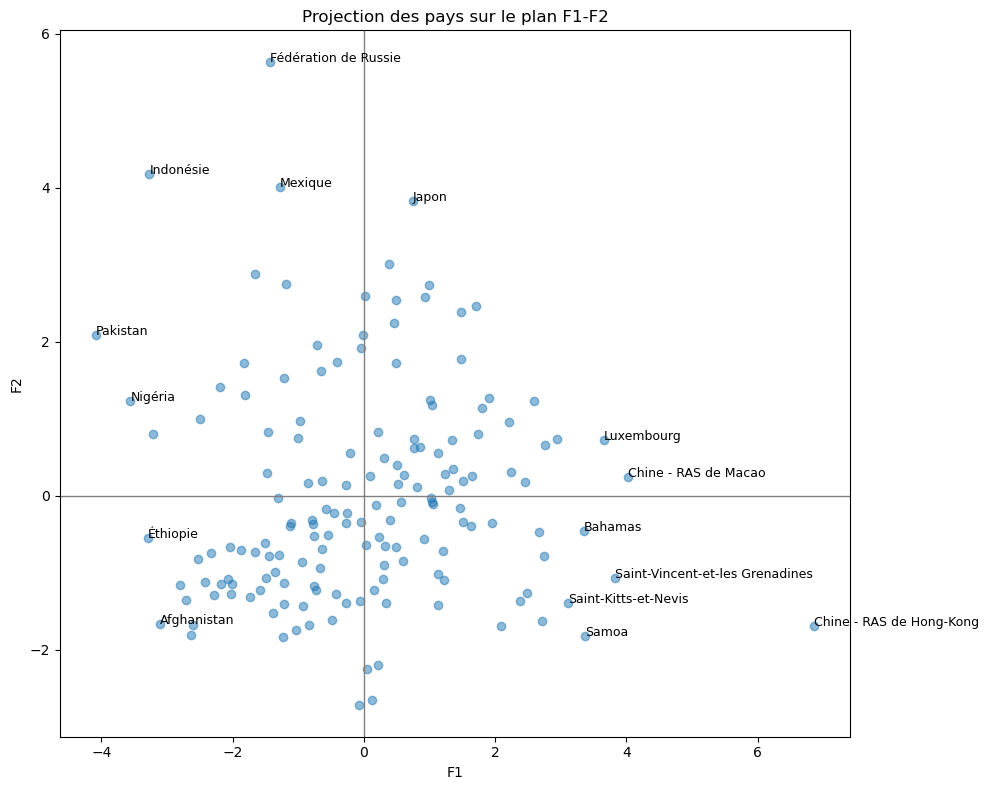

In [58]:
plt.figure(figsize=(10, 8))

plt.scatter(
    projection["F1"],
    projection["F2"],
    alpha=0.5
)

plt.axhline(0, color="grey", linewidth=1)
plt.axvline(0, color="grey", linewidth=1)

for _, ligne in pays_extremes.iterrows():
    plt.text(
        ligne["F1"],
        ligne["F2"],
        ligne["Zone"],
        fontsize=9
    )

plt.xlabel("F1")
plt.ylabel("F2")
plt.title("Projection des pays sur le plan F1-F2")

plt.tight_layout()
plt.show()

In [59]:
# Associer les noms des zones à leurs coordonnées sur F3 et F4.
projection_f34 = pd.DataFrame({
    "Zone": df["Zone"],
    "F3": X_pca[:, 2],
    "F4": X_pca[:, 3]
})

# Calculer la distance à l’origine sur le plan F3–F4.
projection_f34["distance"] = np.sqrt(
    projection_f34["F3"]**2 +
    projection_f34["F4"]**2
)

# Sélectionner les 15 zones les plus éloignées de l’origine sur ce plan.
pays_extremes_f34 = projection_f34.nlargest(15, "distance")

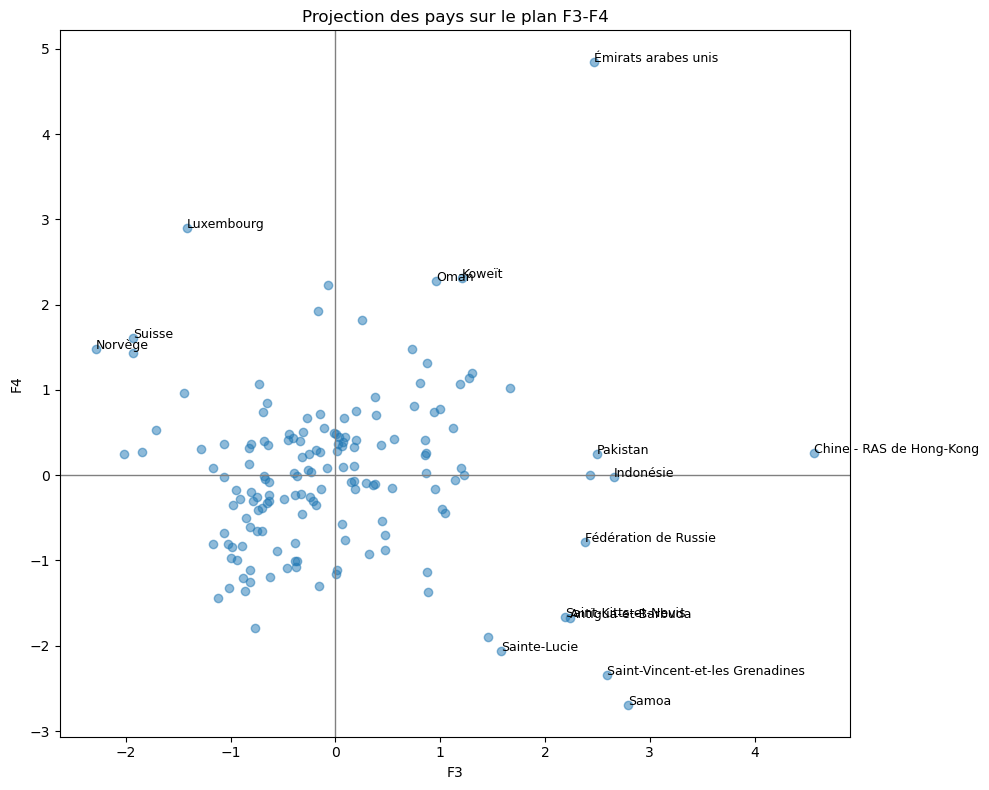

In [60]:
plt.figure(figsize=(10, 8))

plt.scatter(
    projection_f34["F3"],
    projection_f34["F4"],
    alpha=0.5
)

plt.axhline(0, color="grey", linewidth=1)
plt.axvline(0, color="grey", linewidth=1)

for _, ligne in pays_extremes_f34.iterrows():
    plt.text(
        ligne["F3"],
        ligne["F4"],
        ligne["Zone"],
        fontsize=9
    )

plt.xlabel("F3")
plt.ylabel("F4")
plt.title("Projection des pays sur le plan F3-F4")

plt.tight_layout()
plt.show()

## <span style="color: YellowGreen;">6. Comparer les classifications sur 158 zones</span>

### <span style="color: YellowGreen;">6.1. Évaluer la CAH et décrire six groupes</span>

Les contrôles vérifient l’absence de valeurs manquantes et l’alignement entre les lignes de la table et les quatre coordonnées factorielles.

In [61]:
# Vérifier l’effectif et l’absence de valeurs manquantes.
print("Nombre de pays :", len(df))
print("Valeurs manquantes :", df[variables_acp].isna().sum().sum())

Nombre de pays : 158
Valeurs manquantes : 0


In [62]:
print("Nombre de pays dans df :", len(df))
print("Nombre de lignes dans X_pca_4 :", X_pca_4.shape[0])

Nombre de pays dans df : 158
Nombre de lignes dans X_pca_4 : 158


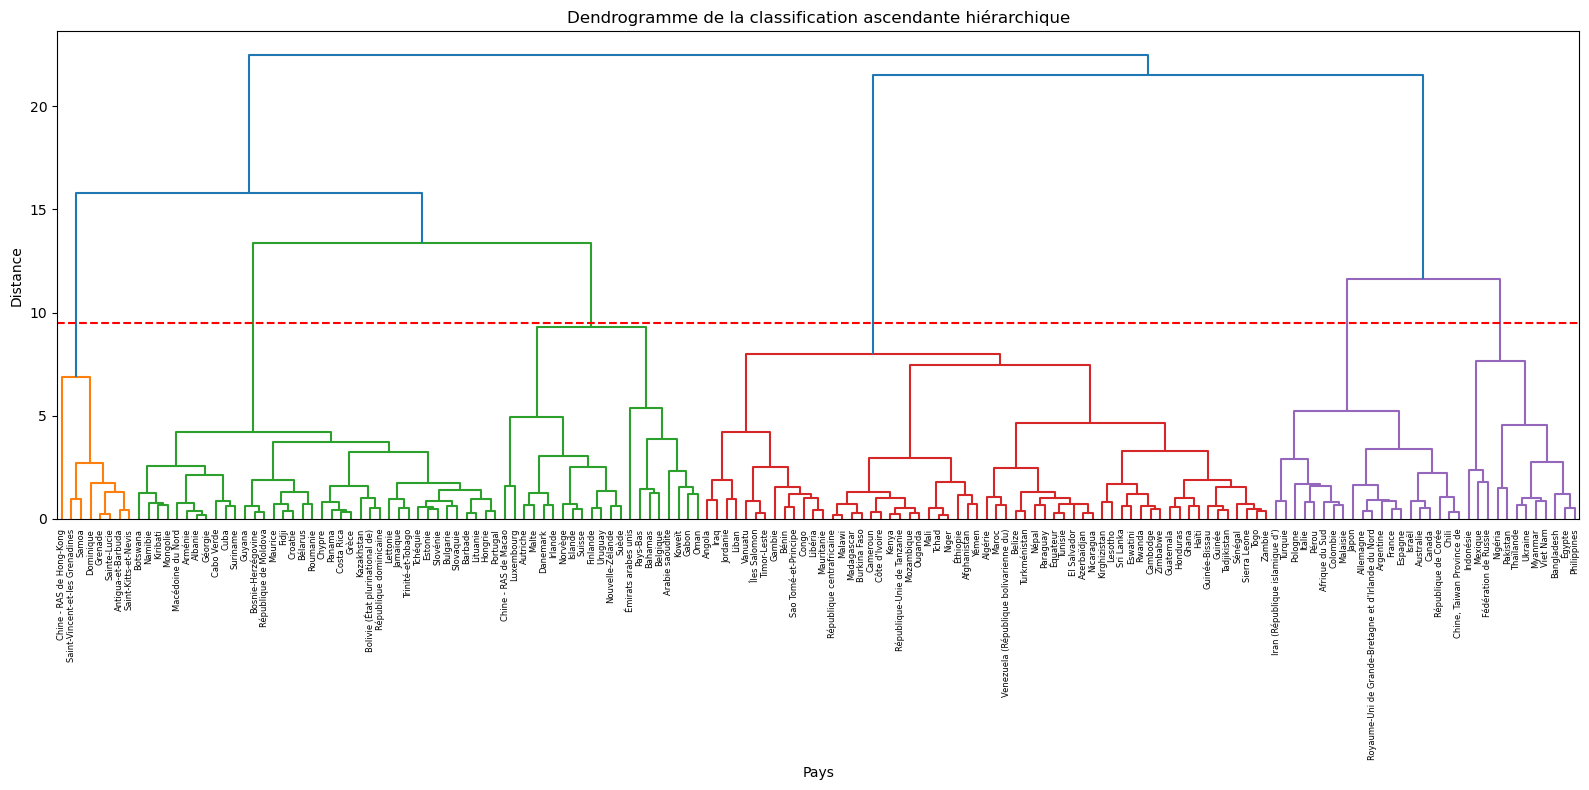

In [63]:
# Construire le dendrogramme de Ward sur les quatre composantes retenues.
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

Z = linkage(X_pca_4, method="ward")

plt.figure(figsize=(16, 8))

dendrogram(
    Z,
    labels=df["Zone"].values,
    leaf_rotation=90,
    leaf_font_size=6
)

plt.axhline(
    y=9.5,
    color="red",
    linestyle="--"
)
plt.title("Dendrogramme de la classification ascendante hiérarchique")
plt.xlabel("Pays")
plt.ylabel("Distance")

plt.tight_layout()
plt.show()

Le dendrogramme permet d’examiner une partition en **six groupes**. Les hauteurs de fusion constituent un repère visuel.

Les scores de silhouette sont calculés pour **2 à 8 groupes**, dans l’espace des quatre composantes retenues.

In [64]:
#from sklearn.cluster import AgglomerativeClustering
#from sklearn.metrics import silhouette_score

for k in range(2, 9):
    
    cah = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    
    labels = cah.fit_predict(X_pca_4)
    
    score = silhouette_score(X_pca_4, labels)
    
    print(f"{k} clusters : silhouette = {score:.3f}")

2 clusters : silhouette = 0.223
3 clusters : silhouette = 0.288
4 clusters : silhouette = 0.307
5 clusters : silhouette = 0.286
6 clusters : silhouette = 0.308
7 clusters : silhouette = 0.323
8 clusters : silhouette = 0.303


La CAH atteint son meilleur score testé avec 7 groupes : 0,323. La solution à 6 groupes obtient 0,308. On conserve **six groupes** comme compromis de description et pour la comparaison ultérieure avec K-means.

In [65]:
# Construire la partition CAH en six groupes.
from sklearn.cluster import AgglomerativeClustering

cah = AgglomerativeClustering(
    n_clusters=6,
    linkage="ward"
)

df["Cluster_CAH"] = cah.fit_predict(X_pca_4) + 1

In [66]:
# Afficher l’effectif de chaque groupe CAH.
df["Cluster_CAH"].value_counts().sort_index()

Cluster_CAH
1    21
2    12
3    59
4     8
5    38
6    20
Name: count, dtype: int64

In [67]:
# afficher les noms des pays
for cluster in sorted(df["Cluster_CAH"].unique()):
    print(f"\nCluster {cluster}")
    print(
        df.loc[df["Cluster_CAH"] == cluster, "Zone"]
        .sort_values()
        .tolist()
    )


Cluster 1
['Arabie saoudite', 'Autriche', 'Bahamas', 'Belgique', 'Chine - RAS de Macao', 'Danemark', 'Finlande', 'Gabon', 'Irlande', 'Islande', 'Koweït', 'Luxembourg', 'Malte', 'Norvège', 'Nouvelle-Zélande', 'Oman', 'Pays-Bas', 'Suisse', 'Suède', 'Uruguay', 'Émirats arabes unis']

Cluster 2
['Bangladesh', 'Fédération de Russie', 'Indonésie', 'Mexique', 'Myanmar', 'Nigéria', 'Pakistan', 'Philippines', 'Thaïlande', 'Ukraine', 'Viet Nam', 'Égypte']

Cluster 3
['Afghanistan', 'Algérie', 'Angola', 'Azerbaïdjan', 'Belize', 'Burkina Faso', 'Bénin', 'Cambodge', 'Cameroun', 'Congo', "Côte d'Ivoire", 'El Salvador', 'Eswatini', 'Gambie', 'Ghana', 'Guatemala', 'Guinée', 'Guinée-Bissau', 'Haïti', 'Honduras', 'Iraq', 'Jordanie', 'Kenya', 'Kirghizistan', 'Lesotho', 'Liban', 'Libéria', 'Madagascar', 'Malawi', 'Mali', 'Maroc', 'Mauritanie', 'Mozambique', 'Nicaragua', 'Niger', 'Népal', 'Ouganda', 'Paraguay', 'Rwanda', 'République centrafricaine', 'République-Unie de Tanzanie', 'Sao Tomé-et-Principe', '

In [68]:
# Calculer les profils moyens standardisés des groupes CAH.
df_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_acp,
    index=df.index
)

df_scaled["Cluster_CAH"] = df["Cluster_CAH"]

profil_cah = (
    df_scaled
    .groupby("Cluster_CAH")[variables_acp]
    .mean()
    .round(2)
    .T
)

profil_cah

Cluster_CAH,1,2,3,4,5,6
Production (milliers de tonnes),-0.33,1.72,-0.44,-0.56,-0.40,1.60
Importations par habitant (kg/personne/an),0.56,-0.51,-0.42,3.53,-0.05,-0.36
Disponibilité alimentaire (kg/personne/an),0.40,-0.32,-0.78,2.22,0.25,0.70
Part importations dans disponibilité intérieure (%),0.53,-0.74,-0.07,1.58,0.04,-0.60
PIB par habitant 2017 ($ US),1.79,-0.53,-0.62,0.08,-0.18,0.58
Population 2017 (milliers),-0.45,2.58,-0.18,-0.59,-0.49,0.65
Croissance population 2000-2017 (%),0.31,-0.19,0.64,-0.61,-0.75,-0.42
Stabilité politique 2017 (0-100),0.98,-1.27,-0.67,1.03,0.55,0.26
Urbanisation 2017 (%),1.20,-0.39,-0.63,-0.71,0.09,0.96


Les profils moyens standardisés des six groupes CAH sont les suivants :

- **Groupe 1 — 21 zones :** PIB par habitant (**+1,79**), urbanisation (**+1,20**), stabilité (**+0,98**) et importations par habitant (**+0,56**) au-dessus de la moyenne ; population inférieure à la moyenne.
- **Groupe 2 — 12 zones :** population (**+2,58**) et production (**+1,72**) élevées ; PIB par habitant, stabilité et indicateurs d’importation inférieurs à la moyenne.
- **Groupe 3 — 59 zones :** PIB par habitant, urbanisation, stabilité et disponibilité alimentaire inférieurs à la moyenne ; croissance démographique supérieure (**+0,64**).
- **Groupe 4 — 8 zones :** population faible, importations par habitant (**+3,53**), disponibilité alimentaire (**+2,22**) et ratio d’importation (**+1,58**) élevés. L’urbanisation reste inférieure à la moyenne (**−0,71**).
- **Groupe 5 — 38 zones :** population et croissance démographique faibles, stabilité supérieure à la moyenne et plusieurs indicateurs proches de la moyenne.
- **Groupe 6 — 20 zones :** production (**+1,60**), urbanisation (**+0,96**) et disponibilité alimentaire (**+0,70**) élevées ; indicateurs d’importation inférieurs à la moyenne.

Ces écarts sont exprimés en **écarts-types par rapport aux 158 zones**, pas en pourcentages.

Cette partition fournit des profils descriptifs distincts. Les groupes importateurs peuvent orienter une recherche de marchés, mais leur intérêt commercial reste à confronter aux coûts, aux débouchés et aux conditions d’accès. Leur interprétabilité ne remplace pas une validation de la stabilité des groupes.

### <span style="color: YellowGreen;">6.2. Évaluer K-means et retenir six groupes</span>

In [69]:
# from sklearn.cluster import KMeans
# from sklearn.metrics import silhouette_score

inerties = []
silhouettes = []

K = range(2, 9)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_pca_4)

    inerties.append(kmeans.inertia_)
    silhouettes.append(
        silhouette_score(X_pca_4, labels)
    )

    print(
        f"{k} clusters : silhouette = "
        f"{silhouettes[-1]:.3f}"
    )

C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


2 clusters : silhouette = 0.280
3 clusters : silhouette = 0.307
4 clusters : silhouette = 0.321


C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


5 clusters : silhouette = 0.320
6 clusters : silhouette = 0.330


C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


7 clusters : silhouette = 0.328
8 clusters : silhouette = 0.309


7 clusters : silhouette = 0.328
8 clusters : silhouette = 0.309


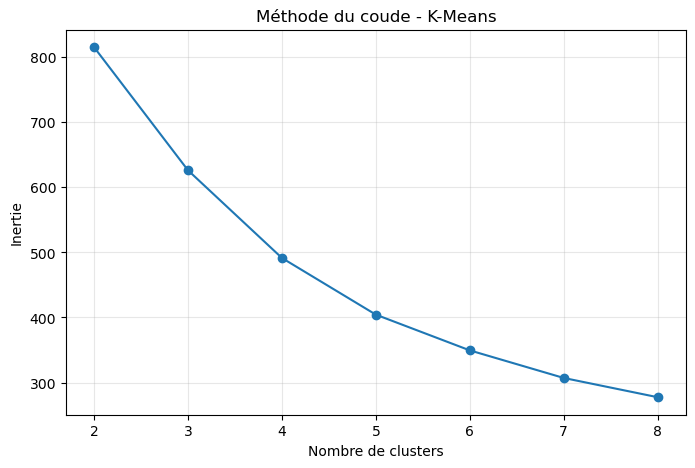

In [70]:
plt.figure(figsize=(8, 5))

plt.plot(K, inerties, marker="o")

plt.xlabel("Nombre de clusters")
plt.ylabel("Inertie")
plt.title("Méthode du coude - K-Means")

plt.xticks(list(K))
plt.grid(alpha=0.3)

plt.show()

Pour la CAH, **7 groupes** maximisent le score testé (**0,323**), contre **0,308** pour six groupes. Pour K-means, le maximum testé est obtenu avec **6 groupes : 0,330**, très proche du score à sept groupes (**0,328**).

La solution à **six groupes** est conservée pour les deux méthodes afin de comparer leurs partitions. Ces scores indiquent une séparation imparfaite : ils ne démontrent pas l’existence d’un nombre de groupes universellement optimal.

K-means est maintenant ajusté avec **6 groupes**. Le tableau de profils présente les moyennes standardisées des neuf indicateurs.

In [71]:
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=20
)

df["Cluster_KMeans"] = kmeans.fit_predict(X_pca_4) + 1

C:\Users\Vecto\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [72]:
df["Cluster_KMeans"].value_counts().sort_index()

Cluster_KMeans
1    20
2    14
3     9
4    47
5    52
6    16
Name: count, dtype: int64

In [73]:
# afficher les noms des pays
for cluster in sorted(df["Cluster_KMeans"].unique()):
    print(f"\nCluster {cluster}")
    print(
        df.loc[df["Cluster_KMeans"] == cluster, "Zone"]
        .sort_values()
        .tolist()
    )


Cluster 1
['Afrique du Sud', 'Allemagne', 'Arabie saoudite', 'Argentine', 'Australie', 'Canada', 'Chili', 'Chine, Taiwan Province de', 'Colombie', 'Espagne', 'France', 'Israël', 'Italie', 'Japon', 'Malaisie', 'Pologne', 'Pérou', "Royaume-Uni de Grande-Bretagne et d'Irlande du Nord", 'République de Corée', 'Venezuela (République bolivarienne du)']

Cluster 2
['Bangladesh', 'Fédération de Russie', 'Indonésie', "Iran (République islamique d')", 'Mexique', 'Myanmar', 'Nigéria', 'Pakistan', 'Philippines', 'Thaïlande', 'Turquie', 'Ukraine', 'Viet Nam', 'Égypte']

Cluster 3
['Antigua-et-Barbuda', 'Bahamas', 'Chine - RAS de Hong-Kong', 'Dominique', 'Grenade', 'Saint-Kitts-et-Nevis', 'Saint-Vincent-et-les Grenadines', 'Sainte-Lucie', 'Samoa']

Cluster 4
['Albanie', 'Arménie', 'Autriche', 'Barbade', 'Bolivie (État plurinational de)', 'Bosnie-Herzégovine', 'Botswana', 'Bulgarie', 'Bélarus', 'Cabo Verde', 'Chypre', 'Costa Rica', 'Croatie', 'Cuba', 'El Salvador', 'Estonie', 'Fidji', 'Finlande', 'G

In [74]:
df_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_acp,
    index=df.index
)

df_scaled["Cluster_KMeans"] = df["Cluster_KMeans"]

profil_kmeans = (
    df_scaled
    .groupby("Cluster_KMeans")[variables_acp]
    .mean()
    .round(2)
    .T
)

profil_kmeans

Cluster_KMeans,1,2,3,4,5,6
Production (milliers de tonnes),1.38,1.83,-0.56,-0.37,-0.48,-0.34
Importations par habitant (kg/personne/an),-0.30,-0.52,3.44,-0.13,-0.40,0.58
Disponibilité alimentaire (kg/personne/an),0.75,-0.24,2.14,0.16,-0.86,0.40
Part importations dans disponibilité intérieure (%),-0.55,-0.76,1.50,-0.06,-0.00,0.69
PIB par habitant 2017 ($ US),0.61,-0.50,0.17,-0.14,-0.63,2.05
Population 2017 (milliers),0.52,2.41,-0.60,-0.47,-0.18,-0.48
Croissance population 2000-2017 (%),-0.37,-0.18,-0.55,-0.71,0.77,0.50
Stabilité politique 2017 (0-100),0.28,-1.27,1.02,0.49,-0.70,1.02
Urbanisation 2017 (%),0.98,-0.19,-0.51,0.13,-0.75,1.28


Les profils moyens standardisés des six groupes k-means corrésponds de près à ceux des 6 groupes CAH. seulement, les numéros des groupes ne sont pas les mêmes:

Groupe 1 Kmeans => Groupe 6 CAH ; 
Groupe 2 Kmeans => Groupe 2 CAH ;
Groupe 3 Kmeans => Groupe 4 CAH ;
Groupe 4 Kmeans => Groupe 5 CAH ;
Groupe 5 Kmeans => Groupe 3 CAH ;
Groupe 6 Kmeans => Groupe 1 CAH ;

### <span style="color: YellowGreen;">6.3. Comparer les deux partitions</span>

Le tableau croisé rapproche les étiquettes CAH et K-means. Les numéros de groupes sont arbitraires et ne doivent pas être comparés directement.

In [75]:
comparaison = pd.crosstab(
    df["Cluster_CAH"],
    df["Cluster_KMeans"],
    margins=True
)

comparaison

Cluster_KMeans,1,2,3,4,5,6,All
Cluster_CAH,,,,,,,
1,1,0,1,3,0,16,21
2,0,12,0,0,0,0,12
3,1,0,0,6,52,0,59
4,0,0,8,0,0,0,8
5,0,0,0,38,0,0,38
6,18,2,0,0,0,0,20
All,20,14,9,47,52,16,158


L’**indice de Rand ajusté (ARI)** mesure l’accord entre deux partitions sans dépendre des numéros attribués aux groupes. Il vaut **1** pour des partitions identiques et environ **0** pour un accord comparable à celui attendu au hasard ; il peut aussi être négatif.

In [76]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    df["Cluster_CAH"],
    df["Cluster_KMeans"]
)

print(f"Adjusted Rand Index : {ari:.3f}")

Adjusted Rand Index : 0.791


L’ARI vaut **0,791**, ce qui indique un accord élevé entre les partitions CAH et K-means à six groupes. Le tableau croisé permet de repérer les correspondances et les différences d’affectation.

Cet accord appuie la convergence des deux méthodes sur ce jeu de données.

## <span style="color: DarkViolet;">7. Visualiser et examiner la composition des groupes</span>

### <span style="color: DarkViolet;">7.1. Projeter les groupes K-means</span>

Les points représentent les zones ; les croix marquent les centres moyens des groupes sur chaque plan. Les couleurs et numéros servent de repères pour chaque graphique

In [77]:
# Préparer une table associant les groupes aux coordonnées factorielles.
df_plot = df.copy()

df_plot["F1"] = X_pca[:, 0]
df_plot["F2"] = X_pca[:, 1]
df_plot["F3"] = X_pca[:, 2]
df_plot["F4"] = X_pca[:, 3]

In [78]:
def projection_clusters(df_plot, cluster_col, axe_x, axe_y, titre):
    plt.figure(figsize=(10, 7))
    
    clusters = sorted(df_plot[cluster_col].unique())
    #couleurs = plt.cm.get_cmap("tab10", len(clusters))
    couleurs = plt.get_cmap("tab10", len(clusters))
    
    for i, cluster in enumerate(clusters):
        sous_df = df_plot[df_plot[cluster_col] == cluster]
        
        plt.scatter(
            sous_df[axe_x],
            sous_df[axe_y],
            s=45,
            alpha=0.75,
            color=couleurs(i),
            label=f"Cluster {cluster}"
        )
        
        # Calculer le centre moyen du groupe dans le plan affiché.
        cx = sous_df[axe_x].mean()
        cy = sous_df[axe_y].mean()
        
        plt.scatter(
            cx, cy,
            s=220,
            marker="X",
            color=couleurs(i),
            edgecolor="black",
            linewidth=1.2
        )
        
        plt.text(
            cx, cy,
            f"C{cluster}",
            fontsize=10,
            ha="center",
            va="center",
            color="black",
            fontweight="bold"
        )

    plt.axhline(0, color="grey", linewidth=1)
    plt.axvline(0, color="grey", linewidth=1)

    plt.xlabel(axe_x)
    plt.ylabel(axe_y)
    plt.title(titre)
    plt.legend(title=cluster_col, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

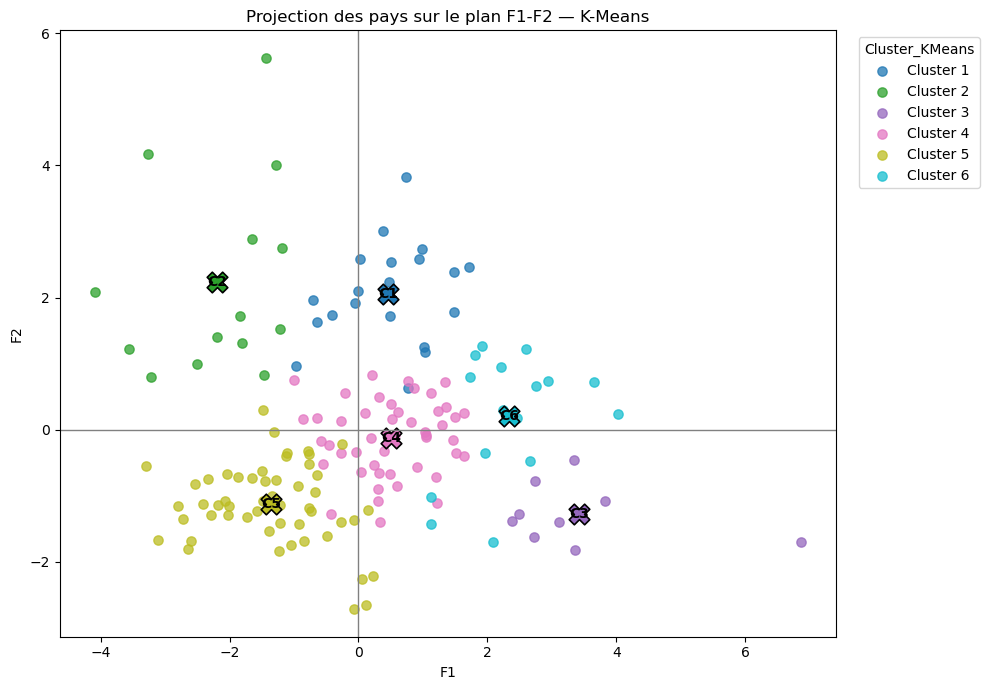

In [79]:
projection_clusters(
    df_plot,
    cluster_col="Cluster_KMeans",
    axe_x="F1",
    axe_y="F2",
    titre="Projection des pays sur le plan F1-F2 — K-Means"
)

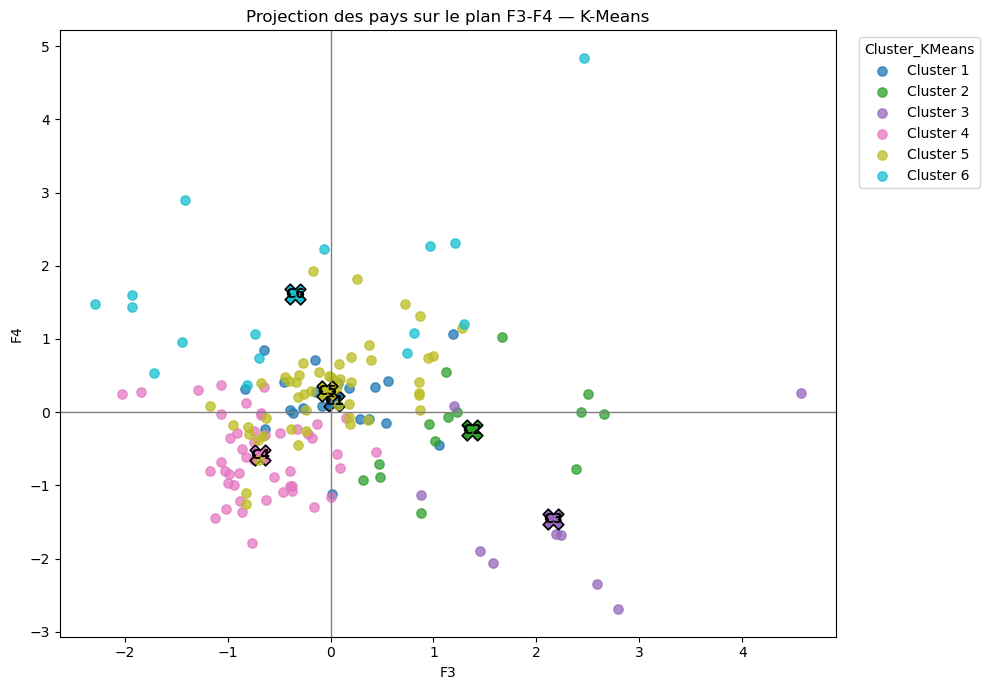

In [80]:
projection_clusters(
    df_plot,
    cluster_col="Cluster_KMeans",
    axe_x="F3",
    axe_y="F4",
    titre="Projection des pays sur le plan F3-F4 — K-Means"
)

### <span style="color: DarkViolet;">7.2. Projeter les groupes de la CAH</span>

Les mêmes plans permettent de comparer les structures visuelles. Attention: Les numéros de groupes sont propres à chaque méthode

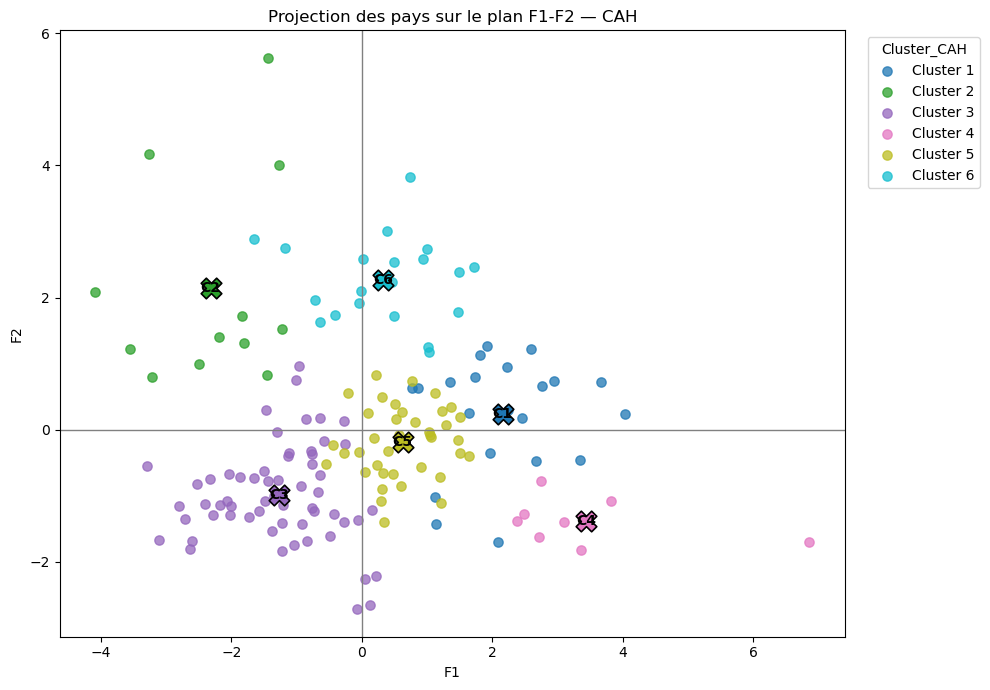

In [81]:
projection_clusters(
    df_plot,
    cluster_col="Cluster_CAH",
    axe_x="F1",
    axe_y="F2",
    titre="Projection des pays sur le plan F1-F2 — CAH"
)

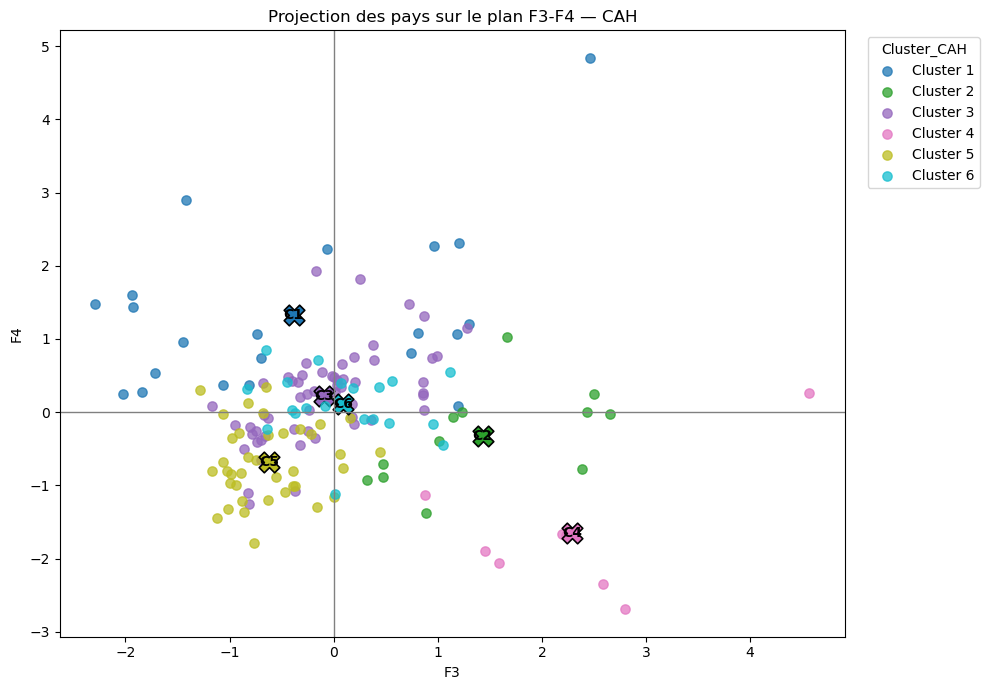

In [82]:
projection_clusters(
    df_plot,
    cluster_col="Cluster_CAH",
    axe_x="F3",
    axe_y="F4",
    titre="Projection des pays sur le plan F3-F4 — CAH"
)

## <span style="color: MediumVioletRed;">8. Comparer les profils et les dispersions</span>

### <span style="color: MediumVioletRed;">8.1. Examiner les moyennes standardisées et les distributions en unités d’origine</span>

Le heatmap présente les moyennes standardisées des groupes K-means. Les boîtes à moustaches suivantes montrent la dispersion des indicateurs dans leurs unités d’origine. Les moyennes et les distributions sont complémentaires.

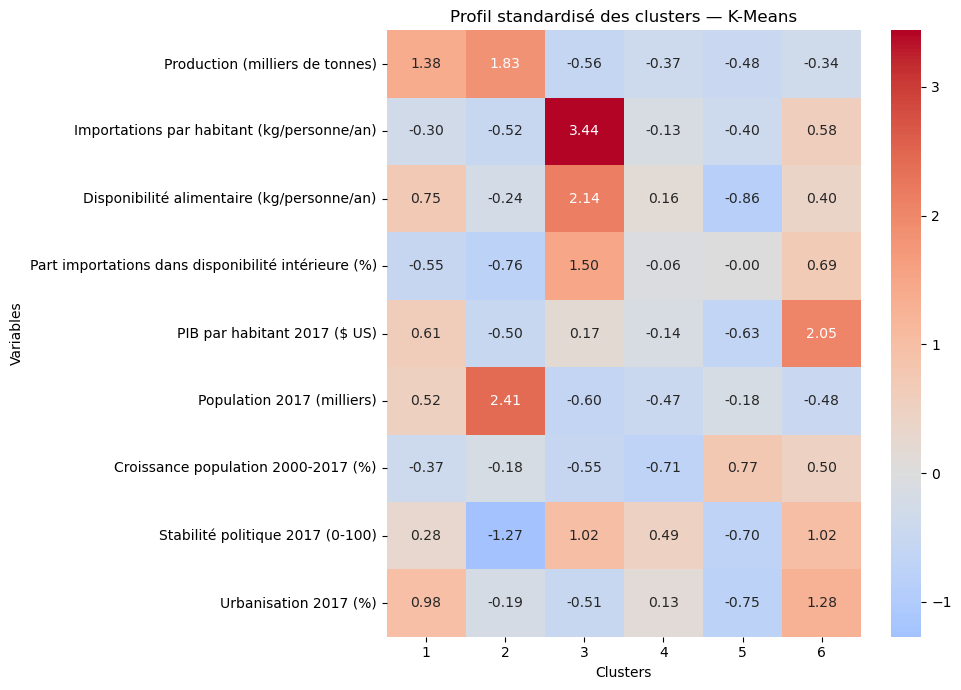

In [83]:
# Représenter les moyennes standardisées des groupes K-means.

import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    profil_kmeans,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Profil standardisé des clusters — K-Means")
plt.xlabel("Clusters")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

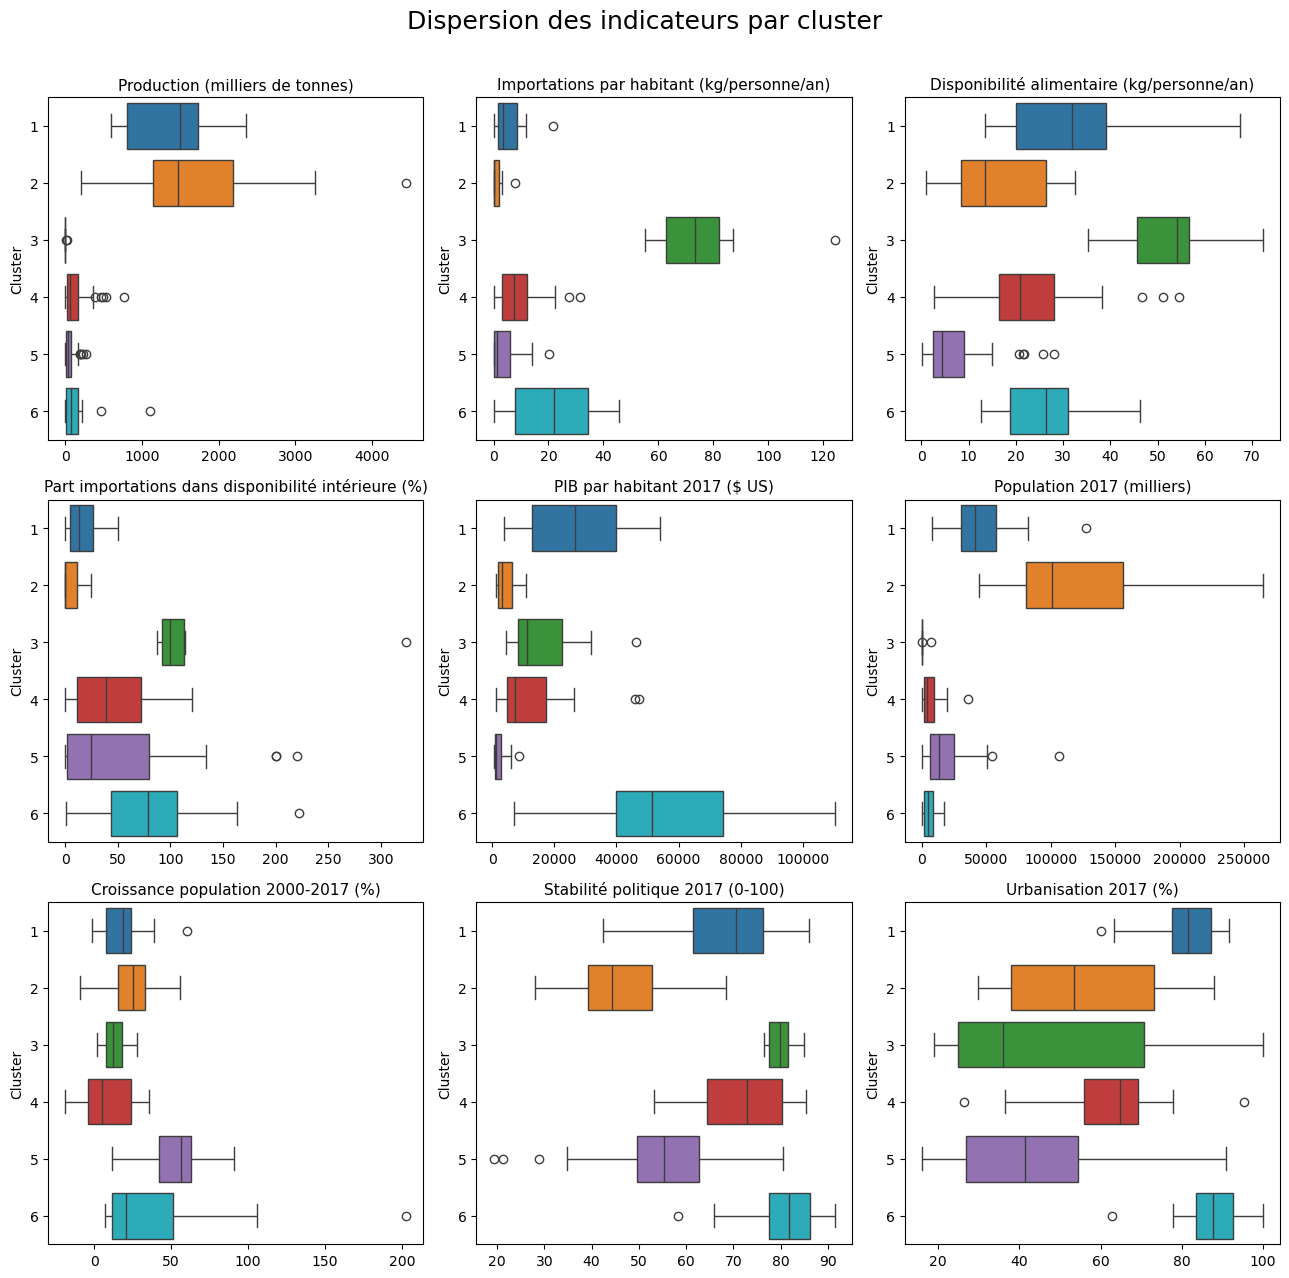

In [84]:
import matplotlib.pyplot as plt
import seaborn as sns

col_cluster = "Cluster_KMeans"

# Convertir les étiquettes en texte pour les traiter comme des catégories.
df[col_cluster] = df[col_cluster].astype(str)

ordre_clusters = ["1", "2", "3", "4", "5", "6"]

palette_clusters = {
    "1": "#1f77b4",
    "2": "#ff7f0e",
    "3": "#2ca02c",
    "4": "#d62728",
    "5": "#9467bd",
    "6": "#17becf"
}

fig, axes = plt.subplots(3, 3, figsize=(13, 13))
axes = axes.flatten()

for i, variable in enumerate(variables_acp):

    ax = axes[i]

    sns.boxplot(
        data=df,
        x=variable,
        y=col_cluster,
        hue=col_cluster,
        order=ordre_clusters,
        hue_order=ordre_clusters,
        palette=palette_clusters,
        orient="h",
        legend=False,
        ax=ax
    )

    ax.set_title(variable, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("Cluster")

plt.suptitle(
    "Dispersion des indicateurs par cluster",
    fontsize=18
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("box-v3.png", dpi=300, bbox_inches="tight")
plt.show()

### <span style="color: MediumVioletRed;">8.2. Comparer les dispersions après standardisation</span>

La seconde série de boîtes à moustaches exprime les indicateurs en écarts-types par rapport à l’ensemble des **158 zones**. La ligne verticale en zéro représente la moyenne générale de chaque indicateur. Les boîtes montrent les médianes et les quartiles ; elles complètent les profils moyens.

In [85]:
df_box = pd.DataFrame(
    X_scaled,
    columns=variables_acp,
    index=df.index
)

df_box["Cluster_KMeans"] = df["Cluster_KMeans"].values

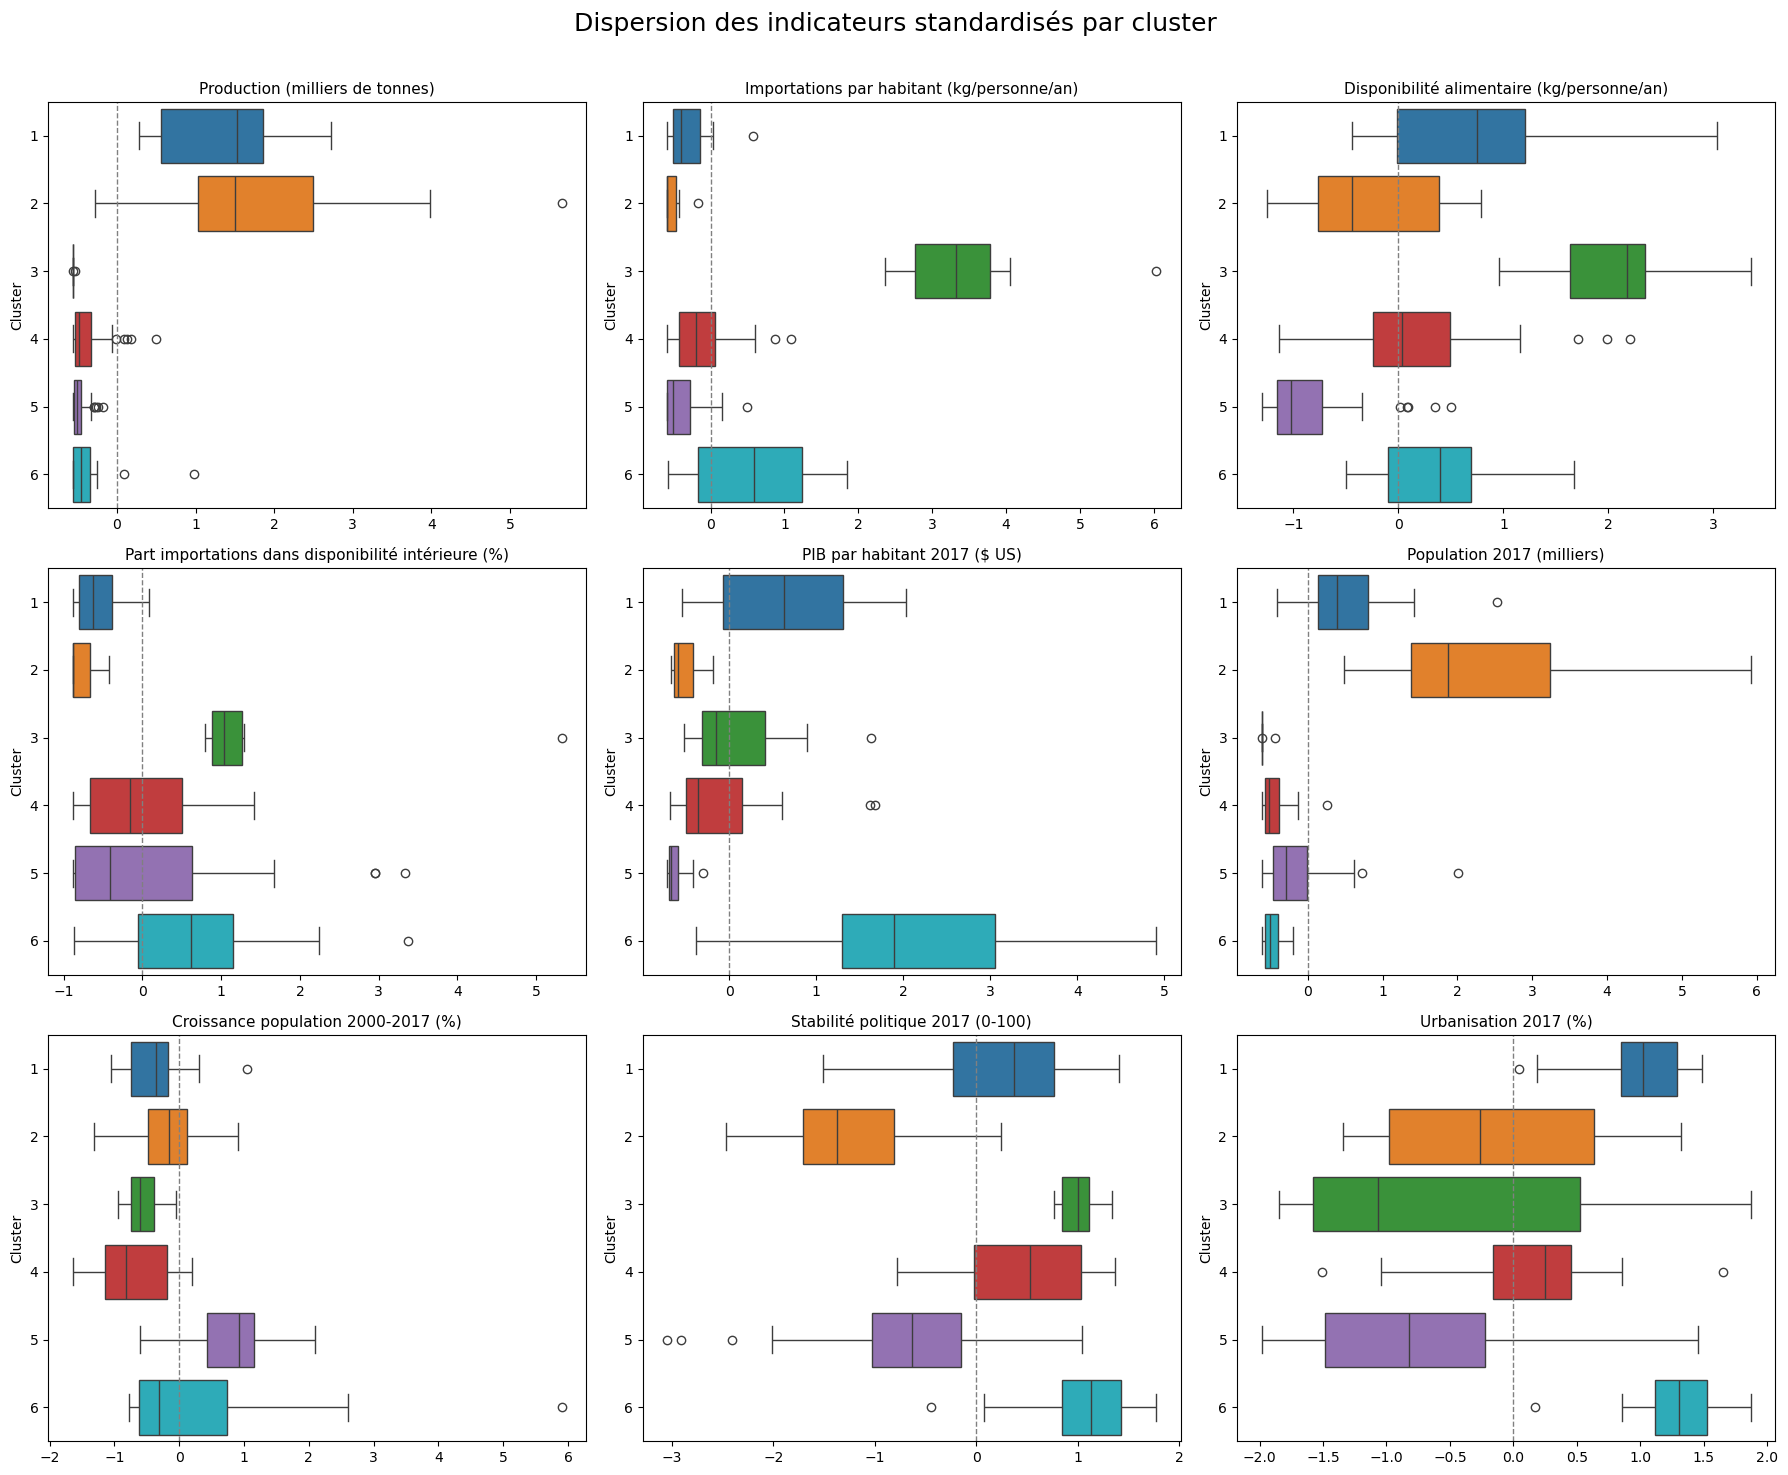

In [86]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, variable in enumerate(variables_acp):

    ax = axes[i]

    sns.boxplot(
        data=df_box,
        x=variable,
        y="Cluster_KMeans",
        hue="Cluster_KMeans",
        order=ordre_clusters,
        hue_order=ordre_clusters,
        palette=palette_clusters,
        orient="h",
        legend=False,
        ax=ax
    )

    # Repérer la moyenne générale de chaque indicateur standardisé (zéro).
    ax.axvline(
        0,
        color="grey",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(variable, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("Cluster")

plt.suptitle(
    "Dispersion des indicateurs standardisés par cluster",
    fontsize=18
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## 9. Synthèse et limites de la segmentation</span>

La partition finale K-means distingue six profils, à lire relativement aux **158 zones** étudiées :

| Groupe | Effectif | Principales caractéristiques |
|---|---:|---|
| 1 | 20 | Production, urbanisation et disponibilité alimentaire supérieures à la moyenne ; indicateurs d’importation plus faibles. |
| 2 | 14 | Population et production élevées ; stabilité et indicateurs d’importation inférieurs à la moyenne. |
| 3 | 9 | Faible population, importations par habitant et disponibilité alimentaire très élevées. |
| 4 | 47 | Population et croissance démographique faibles ; stabilité supérieure à la moyenne et profil alimentaire intermédiaire. |
| 5 | 52 | PIB par habitant, urbanisation, stabilité et disponibilité alimentaire inférieurs à la moyenne ; croissance démographique plus élevée. |
| 6 | 16 | PIB par habitant, urbanisation, stabilité et indicateurs d’importation supérieurs à la moyenne. |

Les groupes **3 et 6** constituent des profils intéressants à examiner. le groupe 6 correspond exactement au groupe 1 de CAH.

L'étude porte sur les données de 2017. Elle présente uniquement un groupe de pays potentiellement intéressants. Elle dois être compléter par des études logistiques, juridiques et autres.